In [ ]:
# Installing the libraries with the specified version.
!pip install scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==1.5.3 -q --user

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 54.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.0/38.0 MB 54.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 49.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This erro

In [2]:
# To filter the warnings
import warnings

warnings.filterwarnings("ignore")

In [2]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import pylab
import scipy.stats as stats

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()
sns.set_style("whitegrid")

# split the data into train and test
from sklearn.model_selection import train_test_split

# To build linear model for statistical analysis and prediction
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.tools.tools import add_constant

# To get diferent metric scores
from sklearn import metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree


#Exploratory Data Analysis

In [10]:
# to upload file from local systerm
from google.colab import files
uploaded = files.upload()

Saving INNHotelsGroup.csv to INNHotelsGroup.csv


In [11]:
df = pd.read_csv("INNHotelsGroup.csv") # Load the dataset from the CSV file into a pandas DataFrame

In [6]:
df.head() # Display the first 5 rows of the dataset

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [12]:
print("Shape of the dataset:", df.shape) # Display the shape of the dataset to know the number of rows and columns

Shape of the dataset: (36275, 19)


In [13]:
print("\nDataset information:") # Display information about the dataset which includes column names, non-null counts, and data types
print(df.info())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64 

In [14]:
print("\nSummary statistics for numerical columns:") # Display summary statistics for numerical columns. This includes count, mean, standard deviation, min, max, and quartiles
print(df.describe(include='all'))


Summary statistics for numerical columns:
       Booking_ID  no_of_adults  no_of_children  no_of_weekend_nights  \
count       36275  36275.000000    36275.000000          36275.000000   
unique      36275           NaN             NaN                   NaN   
top      INN36275           NaN             NaN                   NaN   
freq            1           NaN             NaN                   NaN   
mean          NaN      1.844962        0.105279              0.810724   
std           NaN      0.518715        0.402648              0.870644   
min           NaN      0.000000        0.000000              0.000000   
25%           NaN      2.000000        0.000000              0.000000   
50%           NaN      2.000000        0.000000              1.000000   
75%           NaN      2.000000        0.000000              2.000000   
max           NaN      4.000000       10.000000              7.000000   

        no_of_week_nights type_of_meal_plan  required_car_parking_space  \
count

In [15]:
print("\nSummary statistics for categorical columns:") # Display summary statistics for categorical columns
print(df.describe(include='object'))


Summary statistics for categorical columns:
       Booking_ID type_of_meal_plan room_type_reserved market_segment_type  \
count       36275             36275              36275               36275   
unique      36275                 4                  7                   5   
top      INN36275       Meal Plan 1        Room_Type 1              Online   
freq            1             27835              28130               23214   

       booking_status  
count           36275  
unique              2  
top      Not_Canceled  
freq            24390  


In [16]:
print("\nMissing values in each column:") # Check for missing values in each column
print(df.isnull().sum())


Missing values in each column:
Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64


In [17]:
print("\nNumber of duplicate rows:", df.duplicated().sum()) # Check for duplicate rows in the dataset


Number of duplicate rows: 0


In [18]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist() # Create a list of numerical columns using pandas select_dtypes

categorical_cols = df.select_dtypes(include='object').columns.tolist() # Create a list of categorical columns

print("Numerical columns:") # Print the numerical columns
print(numerical_cols)

print("\nCategorical columns:") # Print the categorical columns
print(categorical_cols)


Numerical columns:
['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'required_car_parking_space', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests']

Categorical columns:
['Booking_ID', 'type_of_meal_plan', 'room_type_reserved', 'market_segment_type', 'booking_status']


##Univariate Analysis for Numerical Features

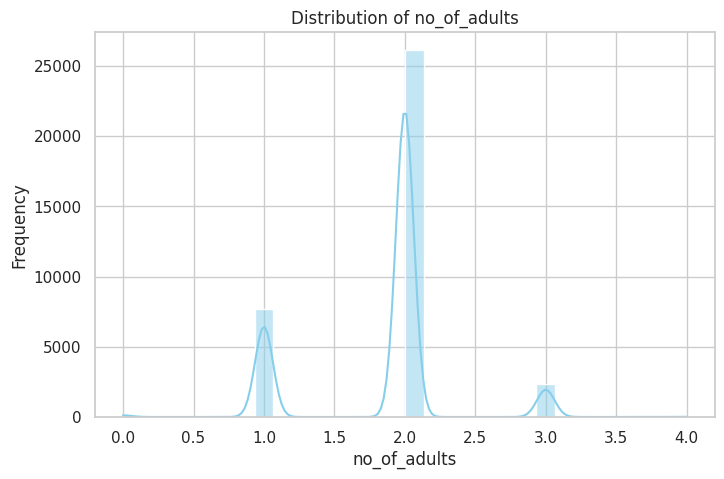

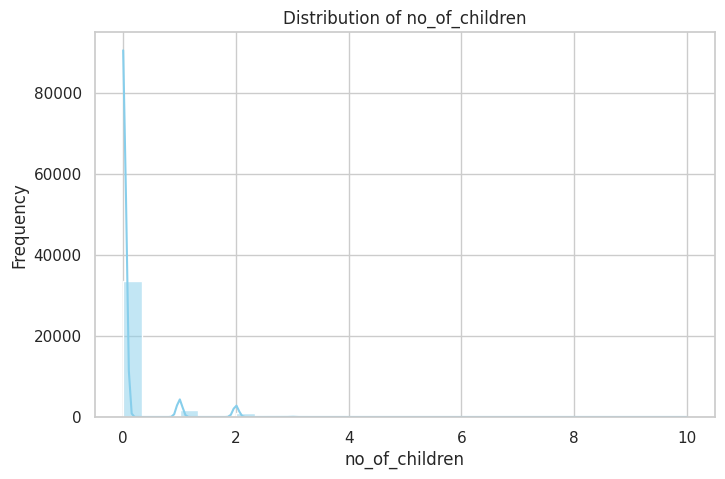

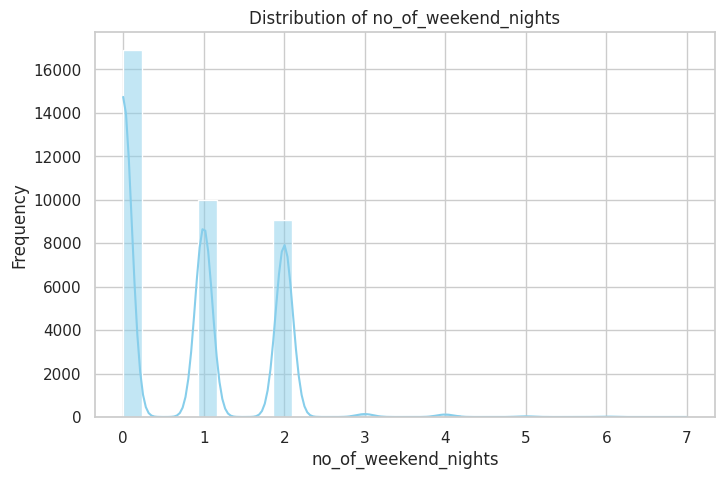

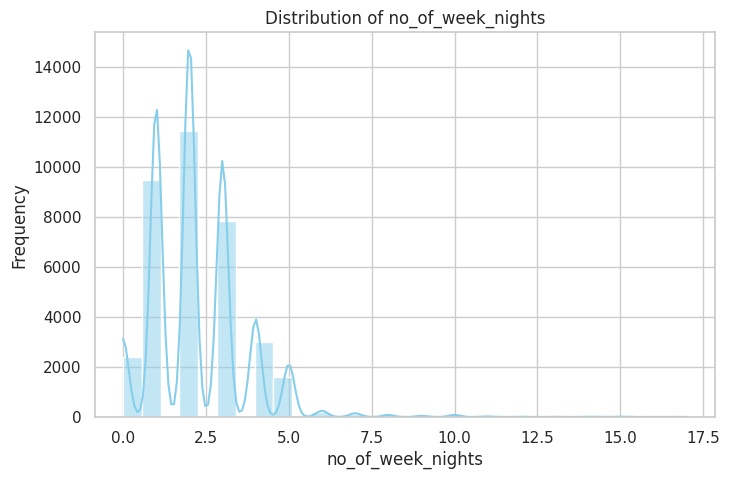

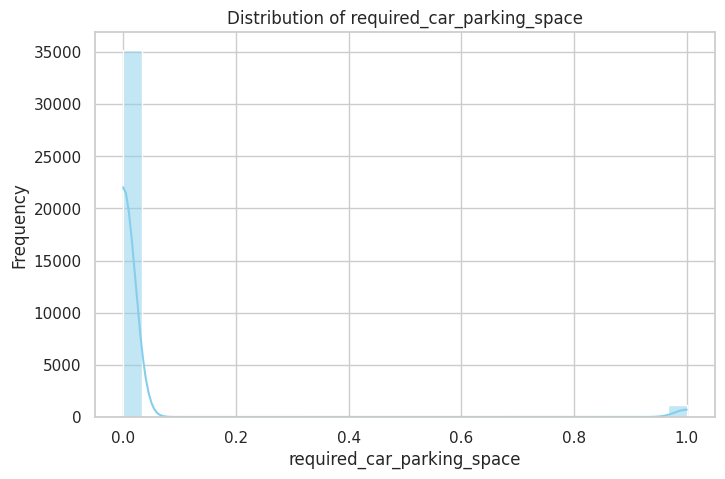

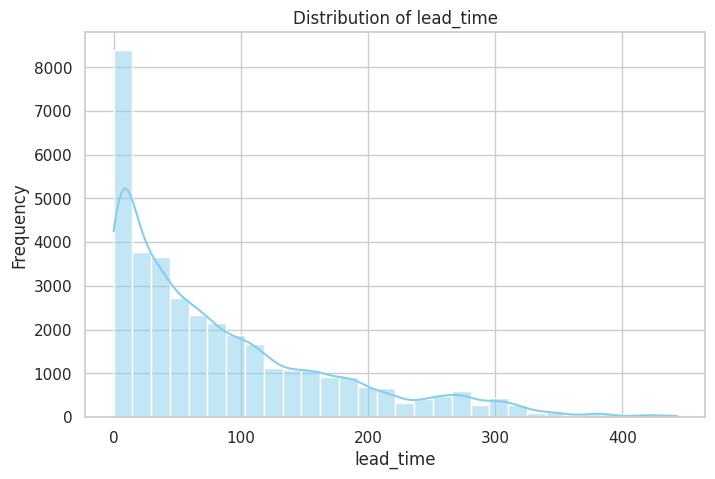

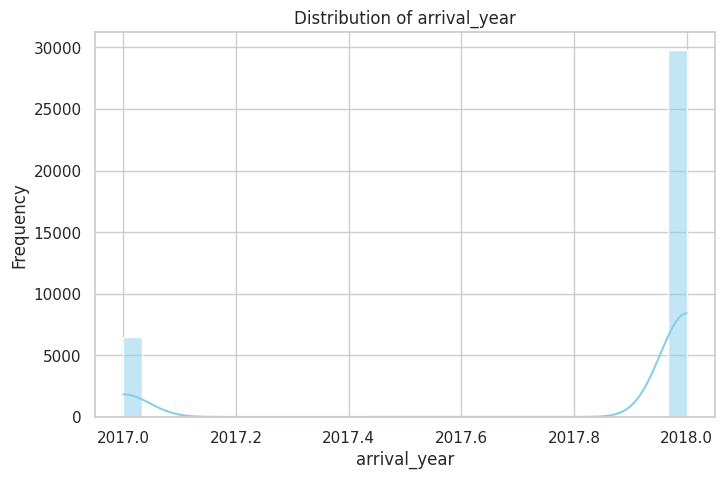

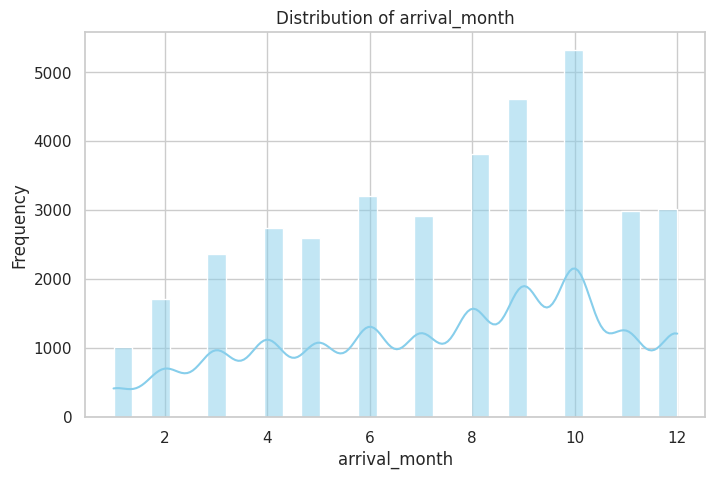

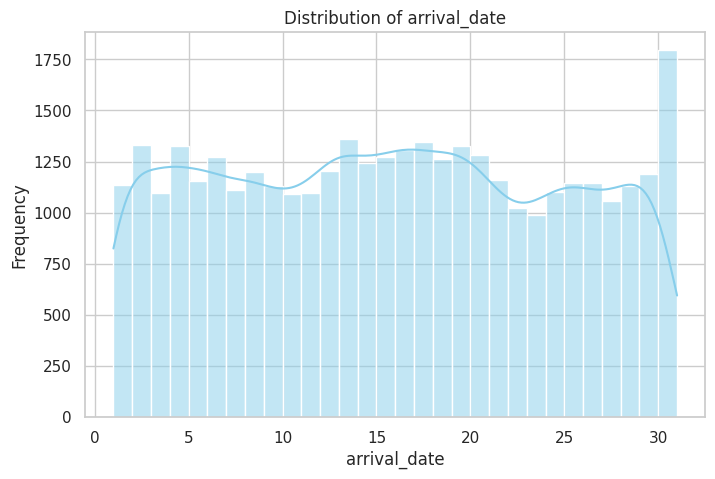

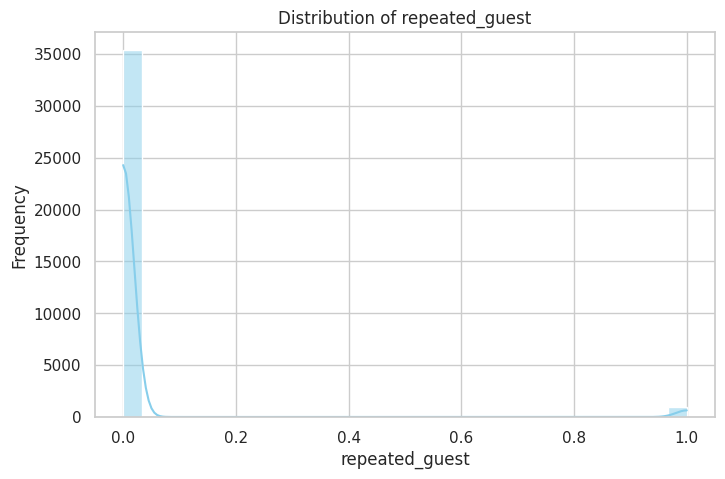

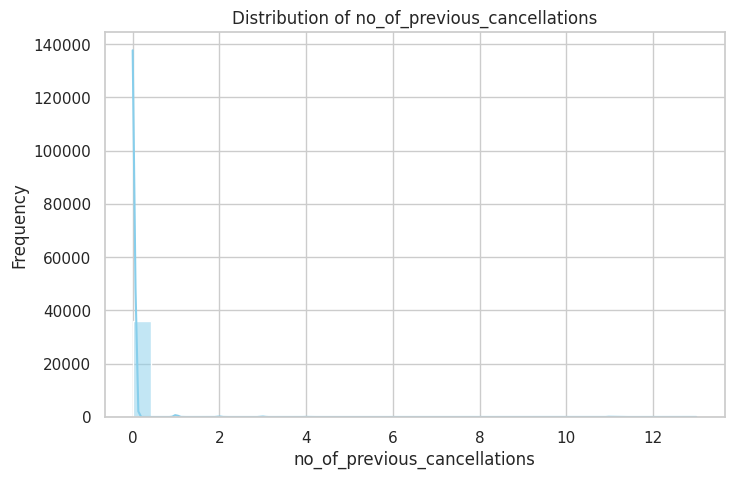

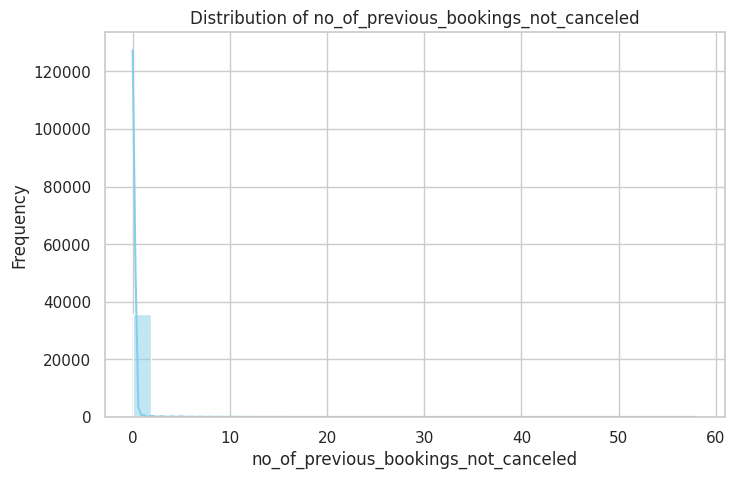

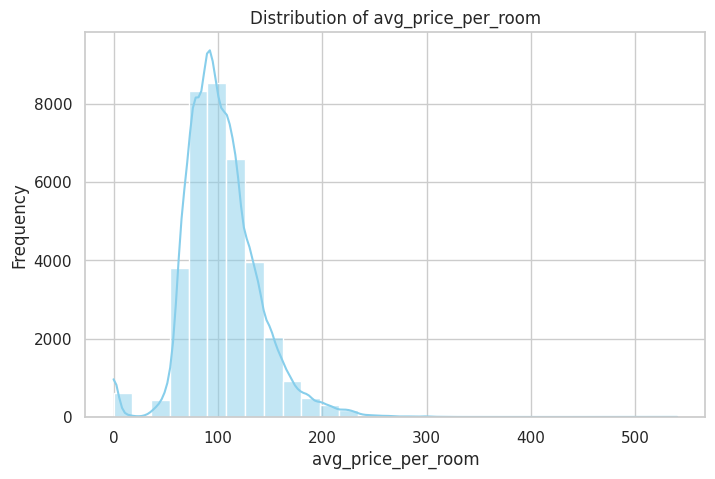

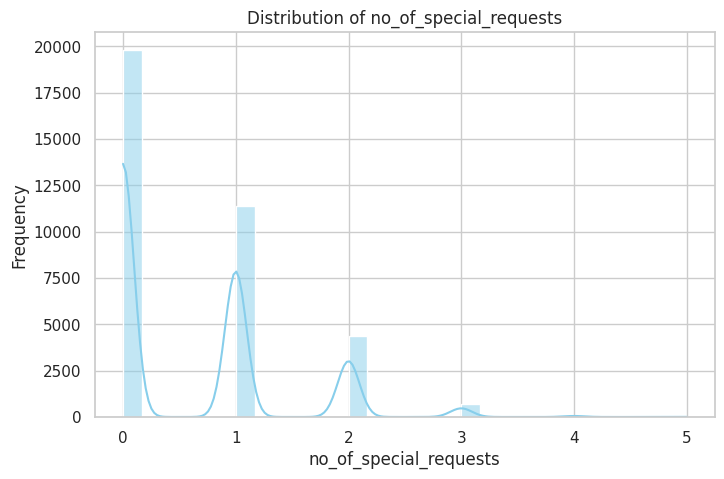

In [19]:
for col in numerical_cols:

        plt.figure(figsize=(8, 5)) # Create a new figure for each column

        sns.histplot(data=df, x=col, kde=True, bins=30, color='skyblue') # Plot histogram with kernel density estimate for distribution view

        plt.title(f"Distribution of {col}") # Set the title of the plot

        plt.xlabel(col) # Label the x-axis

        plt.ylabel("Frequency") # Label the y-axis

        plt.show() # Show the plot


**Insights for This Dataset**

In hotel booking datasets, lead_time is often skewed to the right.

There may also be some high-value outliers in avg_price_per_room, which could be right-skewed.


The number of children and the number of special requests may be concentrated at low values.

Some features, like arrival_year, may only have a few unique values, so you may not need to interpret histograms in the usual way.

##Boxplots for Numerical Features to Detect Outliers

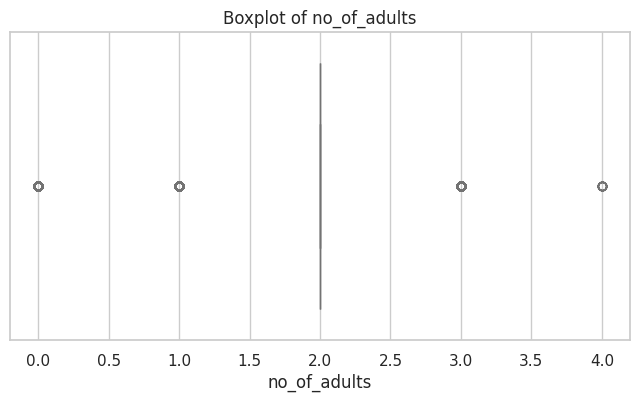

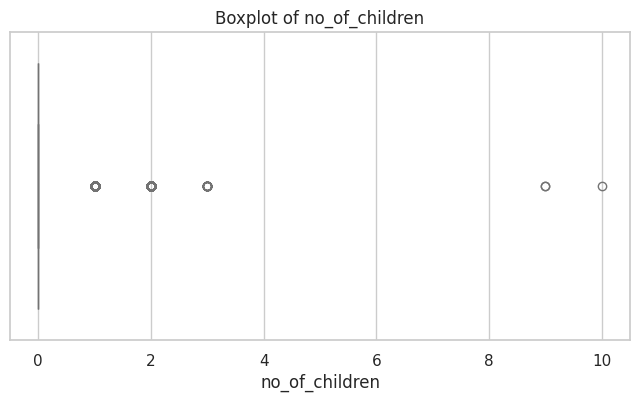

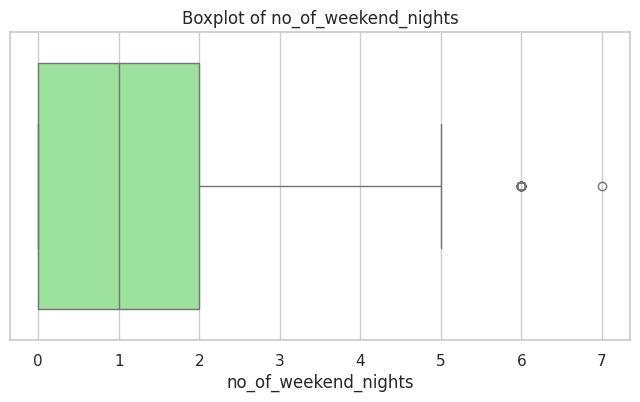

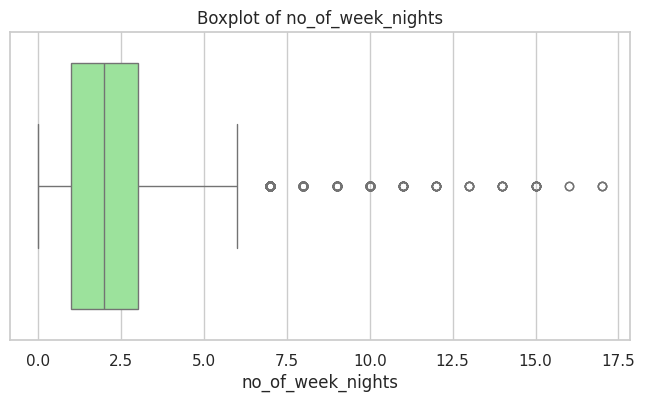

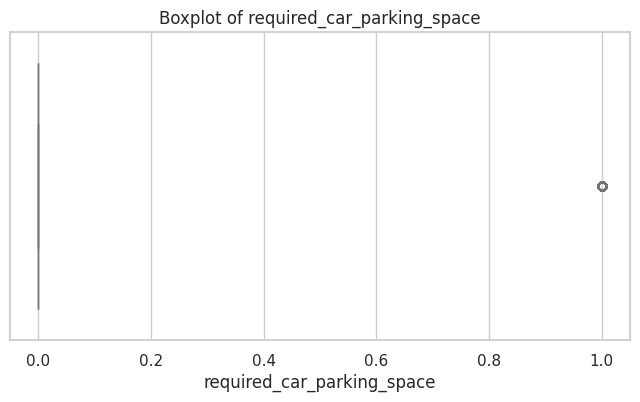

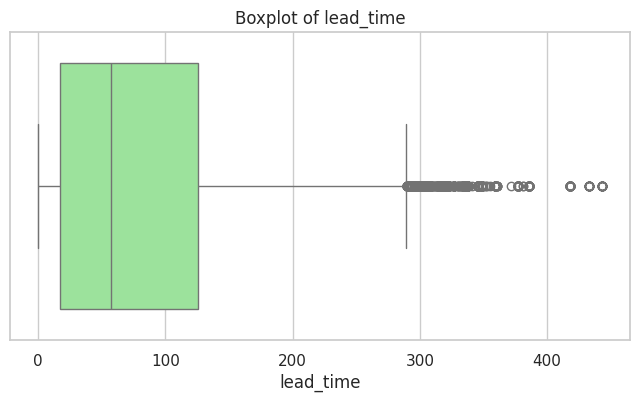

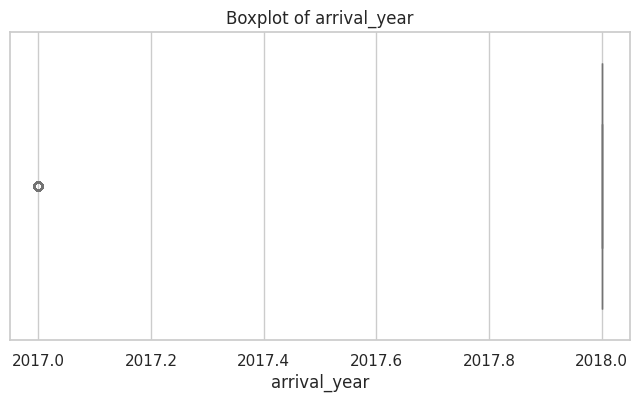

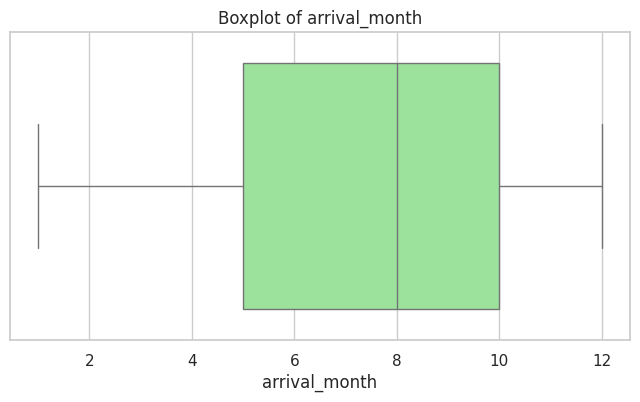

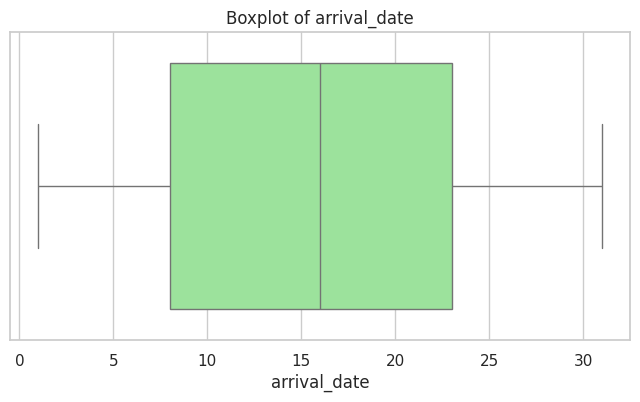

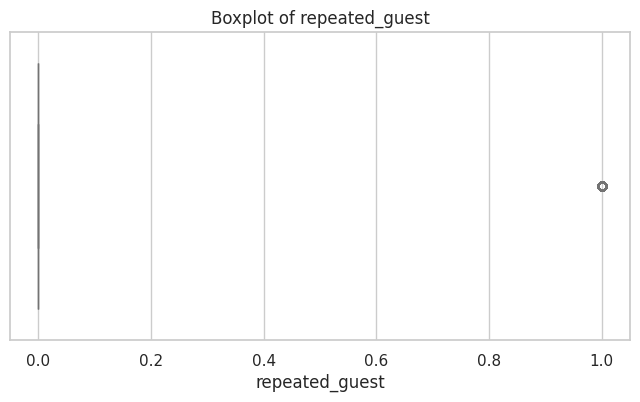

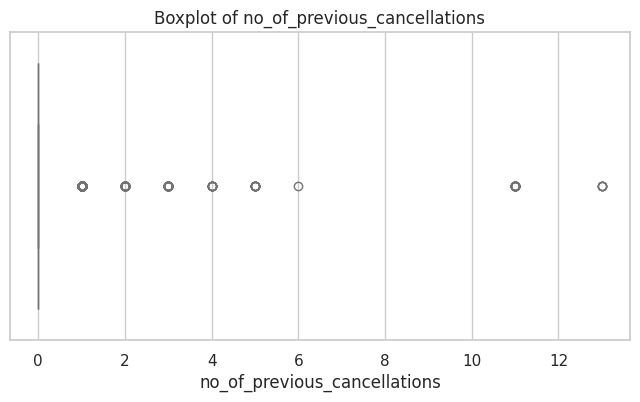

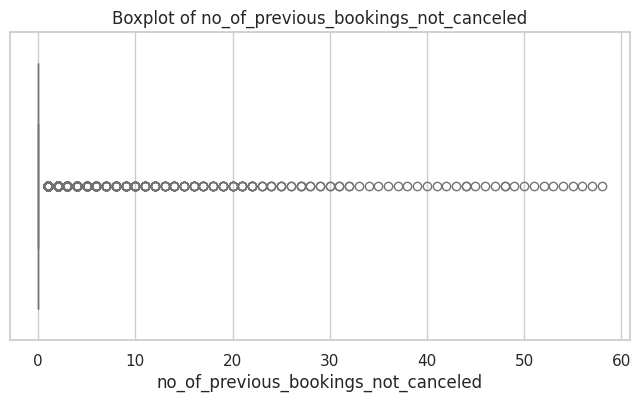

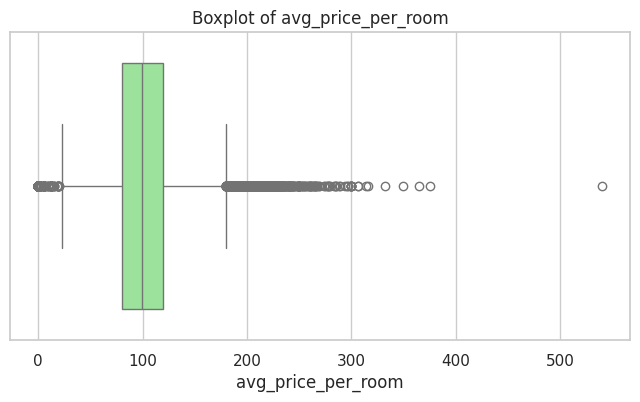

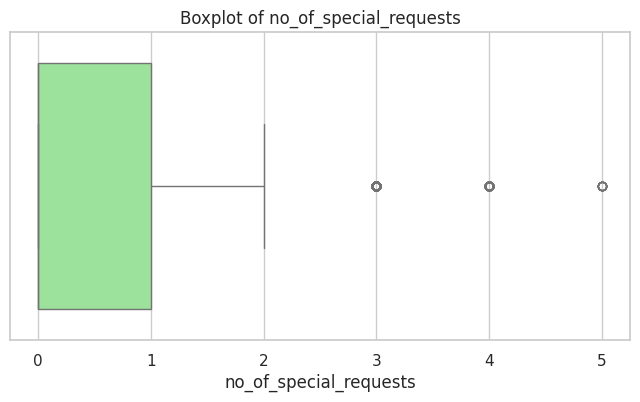

In [20]:
for col in numerical_cols: # To identify outliers

        plt.figure(figsize=(8, 4)) # Creates a new figure for each column

        sns.boxplot(data=df, x=col, color='lightgreen') # Draws the boxplot

        plt.title(f"Boxplot of {col}") # Sets the title

        plt.show() # Shows the plot


Dots that go beyond the whiskers show possible outliers.

Long whiskers mean that something is spread out.

A box that is very compressed and has a lot of outliers suggests that it is skewed.

##Univariate Analysis for Categorical Features

/tmp/ipykernel_1010/94198124.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(   # Plot category frequencies


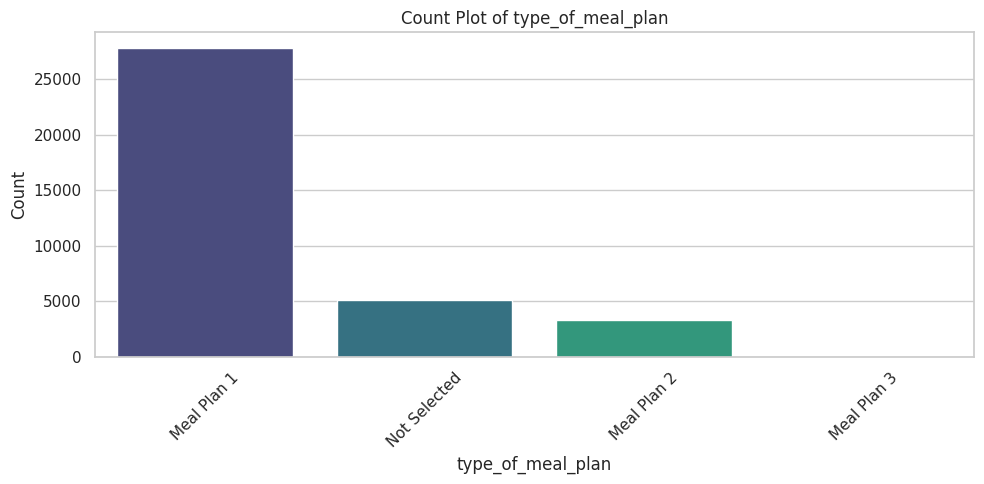

/tmp/ipykernel_1010/94198124.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(   # Plot category frequencies


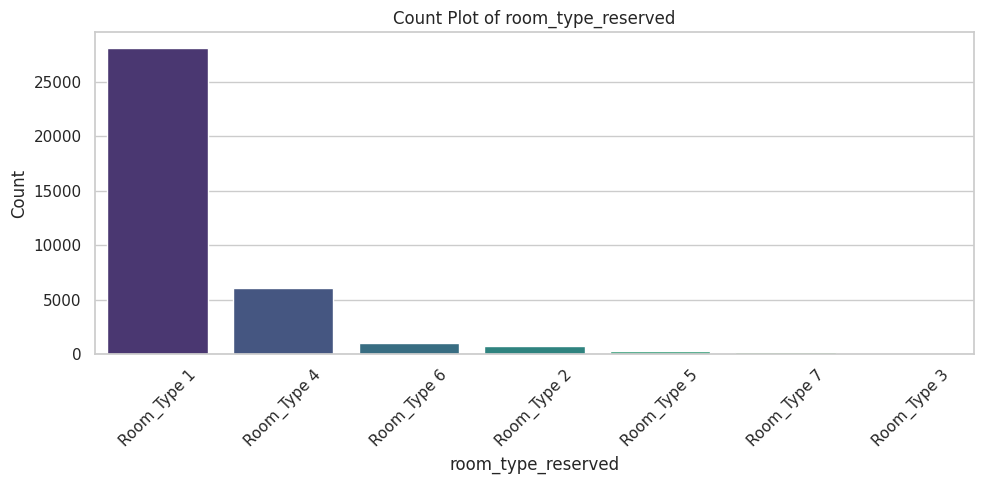

/tmp/ipykernel_1010/94198124.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(   # Plot category frequencies


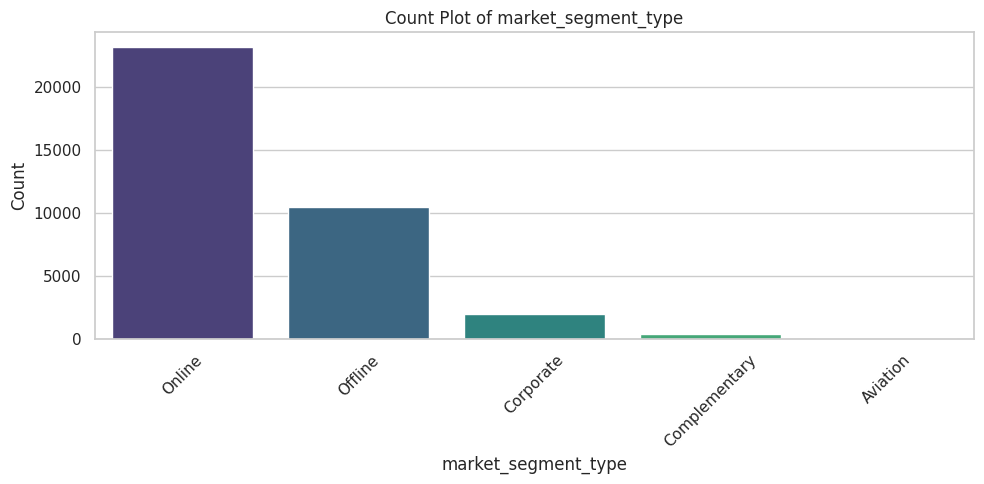

/tmp/ipykernel_1010/94198124.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(   # Plot category frequencies


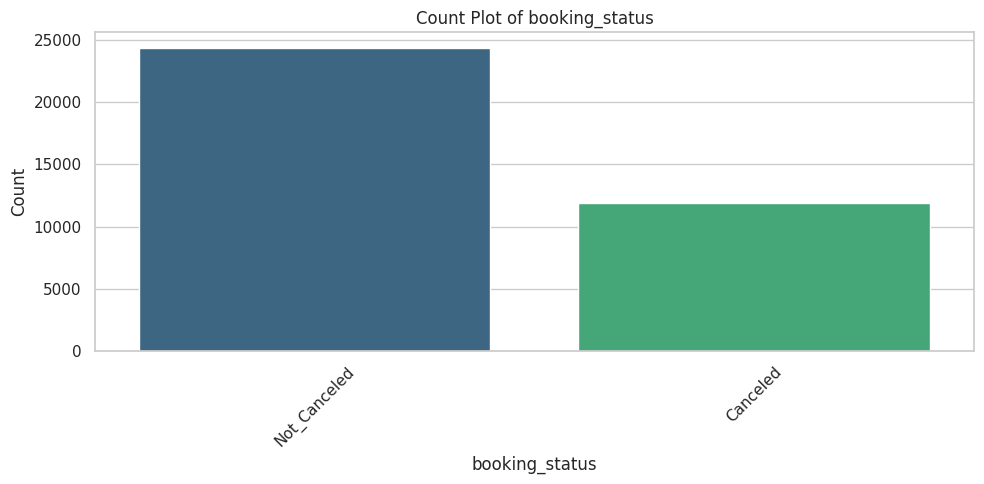

In [21]:
categorical_cols_for_eda = [    # Booking_ID is excluded because it is just a unique identifier
    'type_of_meal_plan',
    'room_type_reserved',
    'market_segment_type',
    'booking_status'
]

for col in categorical_cols_for_eda: # Loop through selected categorical columns

       plt.figure(figsize=(10, 5))  # Create a figure

       sns.countplot(   # Plot category frequencies
        data=df,
        x=col,
        order=df[col].value_counts().index,
        palette='viridis'
    )

       plt.xticks(rotation=45)   # Rotate x labels for readability

       plt.title(f"Count Plot of {col}") # Add plot title and labels
       plt.xlabel(col)
       plt.ylabel("Count")
       plt.tight_layout()   # Improve spacing
       plt.show()  # Show the plot

**Insights**

There are more Not_Canceled bookings than Cancelled ones in booking_status.

This means that cancellation is not the most common class.

When making a model, you should keep the class distribution in mind.

##Analyze the Target Variable Separately

booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64
booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: proportion, dtype: float64


/tmp/ipykernel_1010/3482408263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='booking_status', palette='Set2')


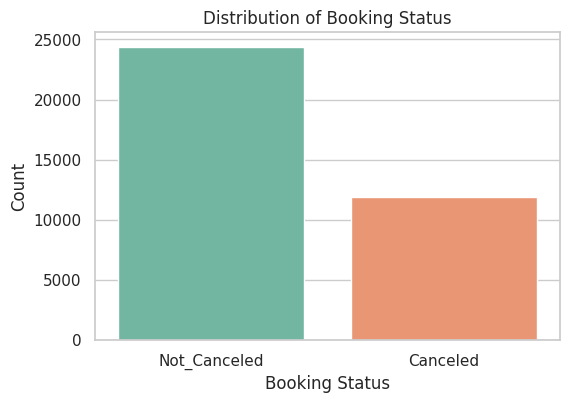

In [22]:
print(df['booking_status'].value_counts())  # Display the count of each class in booking_status
print(df['booking_status'].value_counts(normalize=True) * 100)  # Display the percentage distribution of each class in booking_status
plt.figure(figsize=(6, 4))  # Create a count plot for booking_status
sns.countplot(data=df, x='booking_status', palette='Set2')
plt.title("Distribution of Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Count")
plt.show()

**Insights**

Not_Canceled bookings are higher than Canceled.

This tells us the dataset is somewhat imbalanced, but not extremely imbalanced.

##Bivariate Analysis: Numerical Features vs Booking Status

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


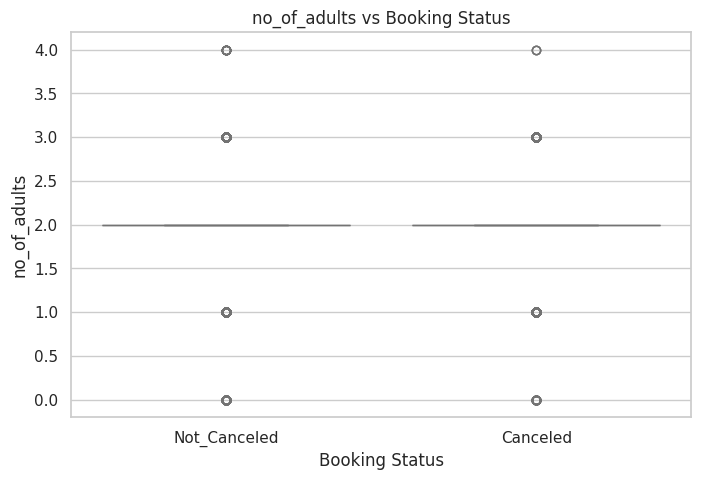

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


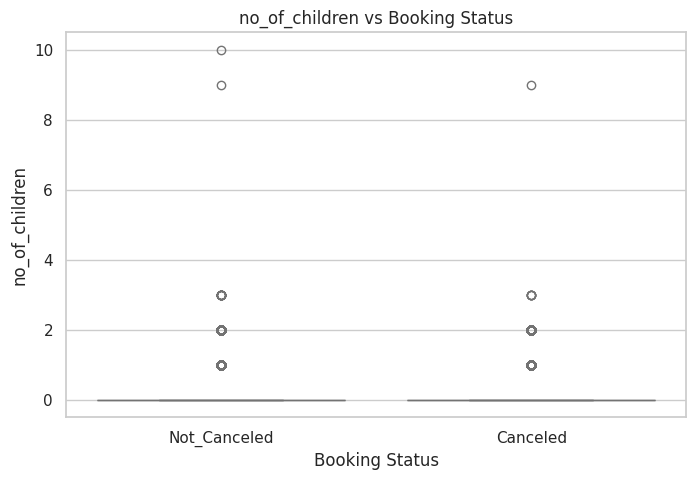

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


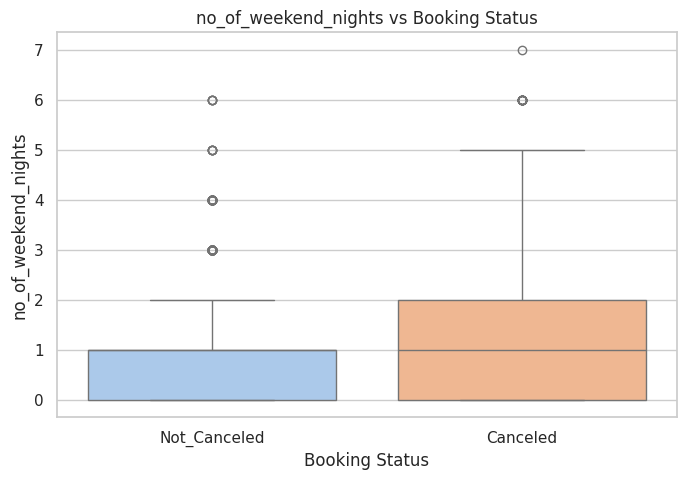

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


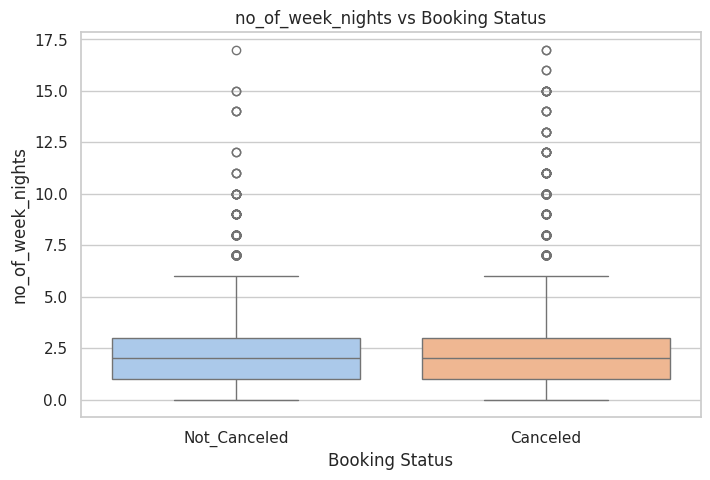

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


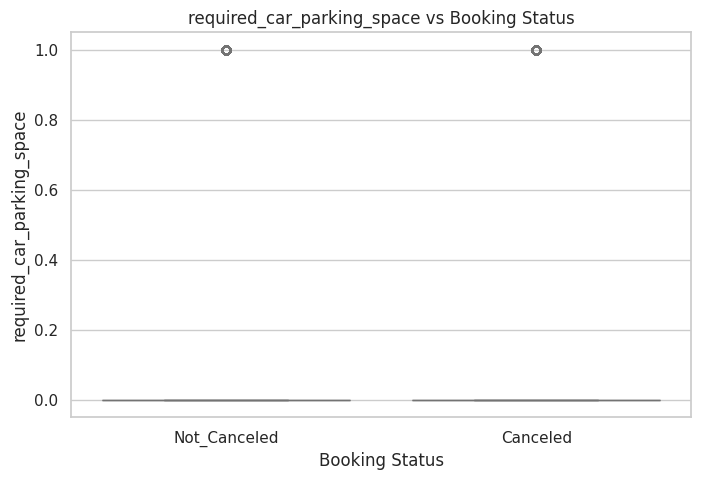

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


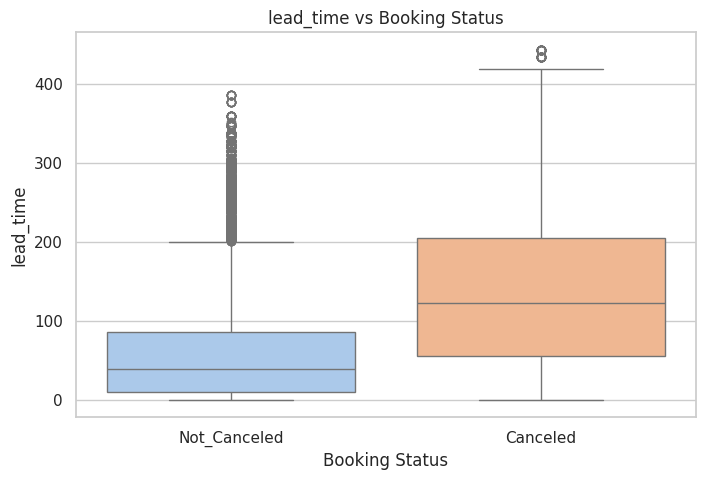

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


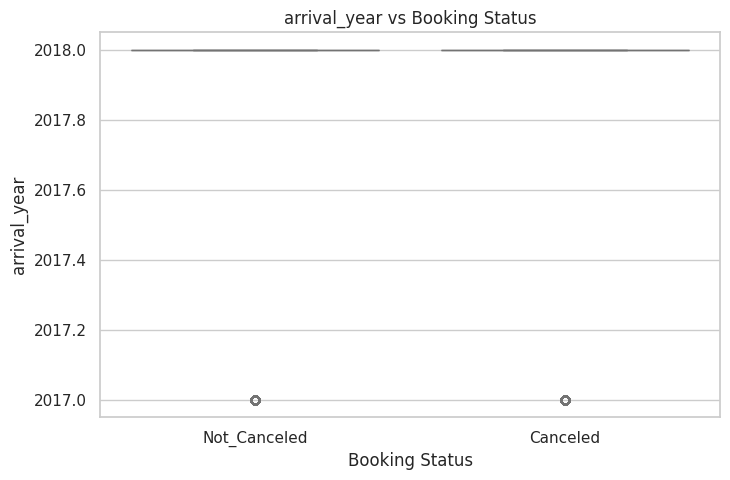

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


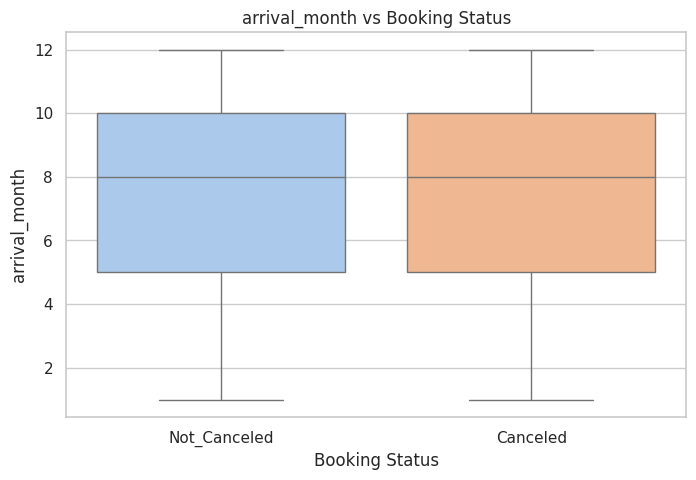

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


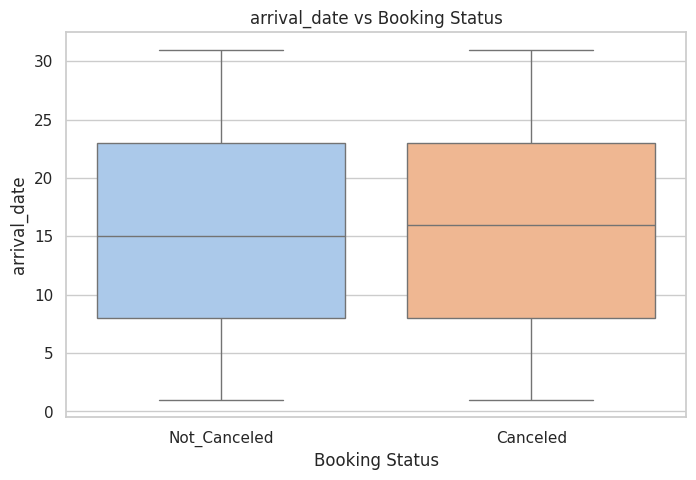

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


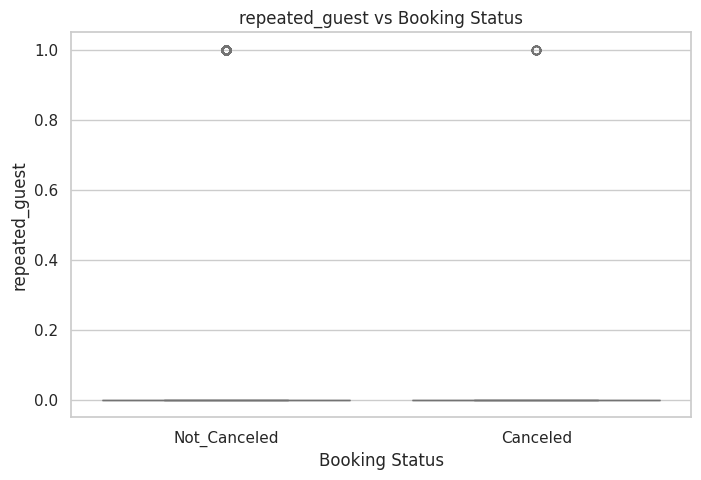

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


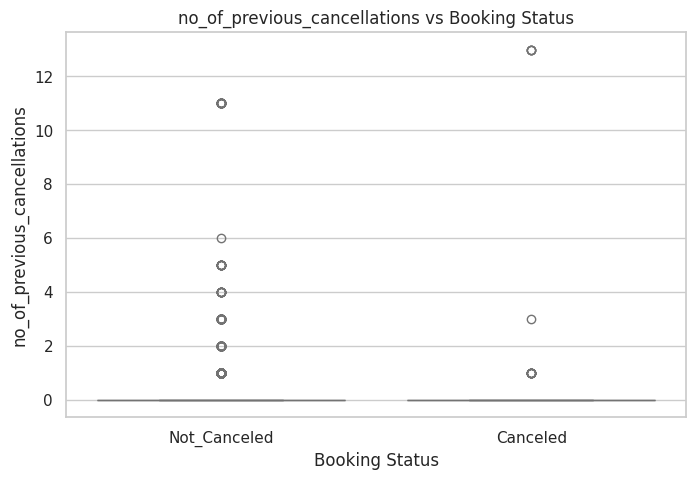

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


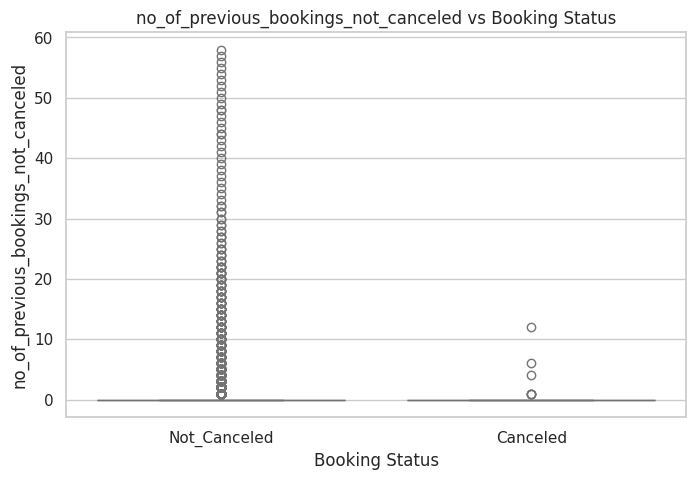

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


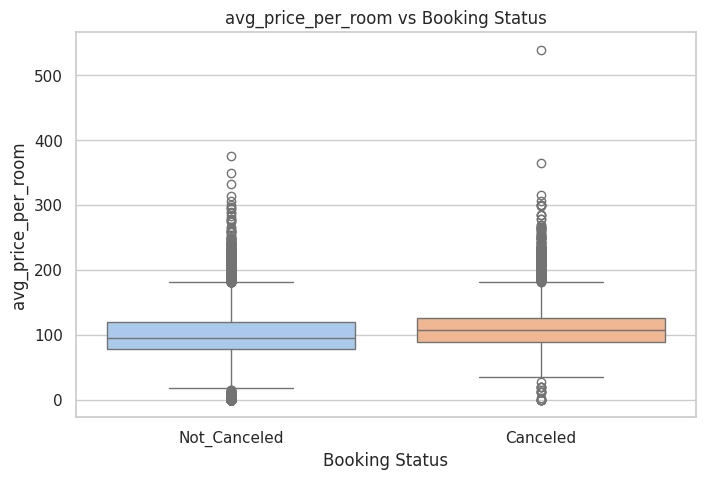

/tmp/ipykernel_1010/2986194796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes


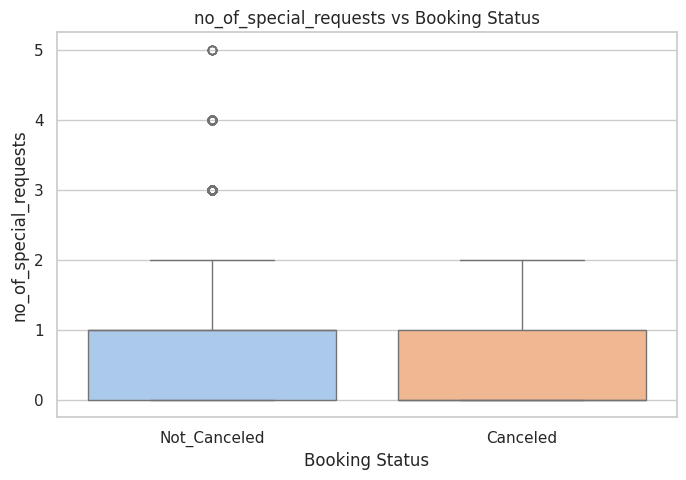

In [23]:
for col in numerical_cols: # Create boxplots of each numerical feature against booking_status
        plt.figure(figsize=(8, 5))  #Here we include all numerical columns for completeness

        sns.boxplot(data=df, x='booking_status', y=col, palette='pastel') # Draw the boxplot to compare distribution across booking_status classes

        plt.title(f"{col} vs Booking Status") # Set plot title

        plt.xlabel("Booking Status")  # Label axes
        plt.ylabel(col)

        plt.show()  # Show the plot


**Insights**

Higher lead_time may be associated with more cancellations.

More special_requests may indicate stronger booking intent, so cancellations may be lower.

Previous cancellations may indicate repeat cancellation behavior.

##Bivariate Analysis: Categorical Features vs Booking Status

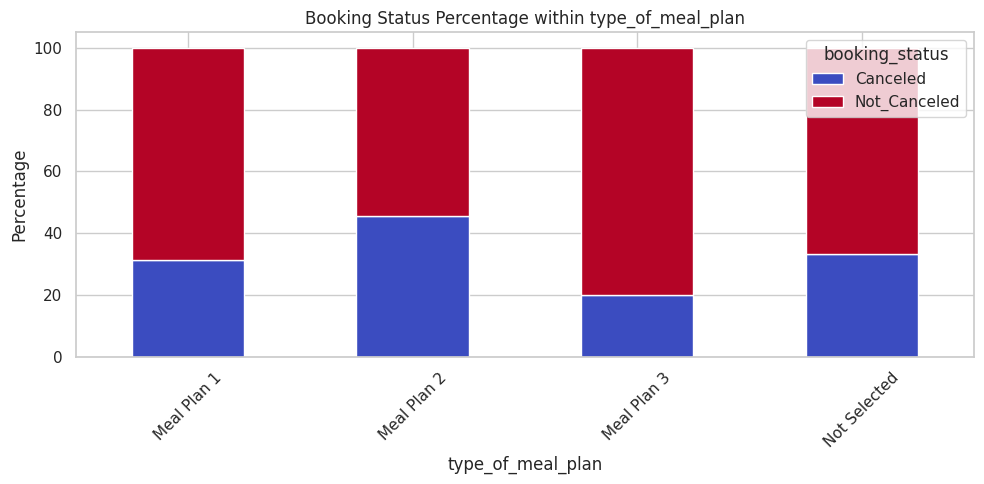

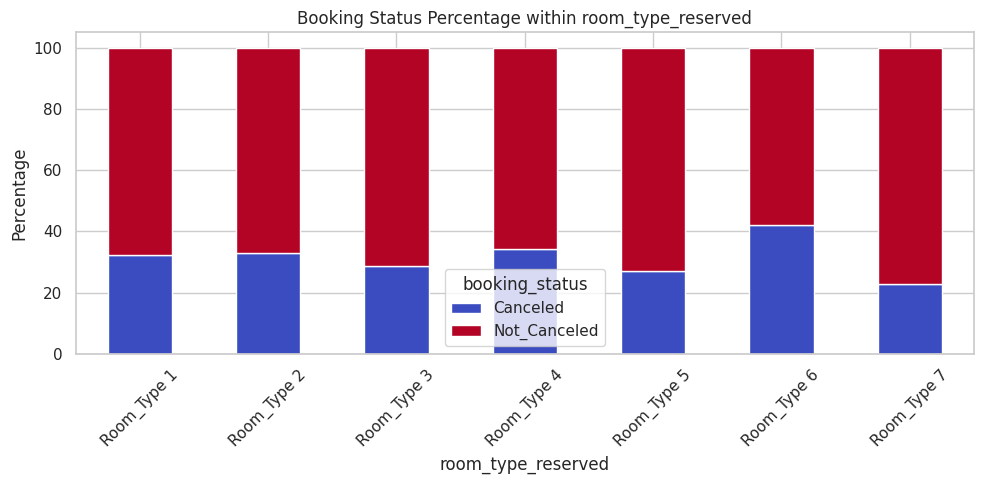

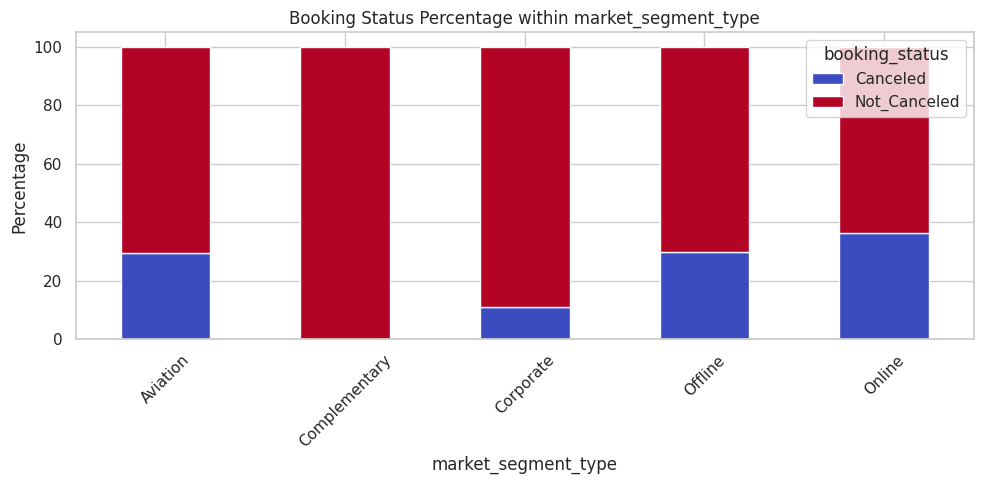

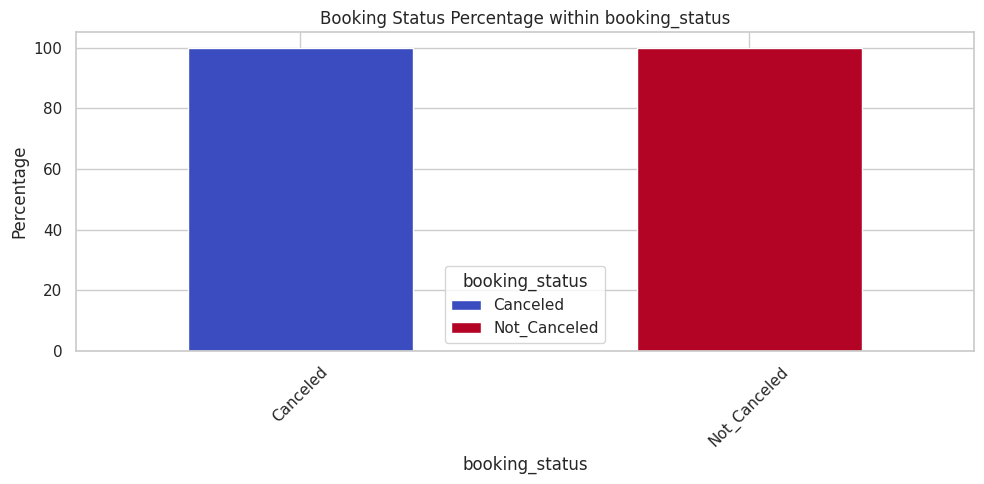

In [24]:
for col in categorical_cols_for_eda: # Loop through selected categorical columns

    crosstab_percent = pd.crosstab(df[col], df['booking_status'], normalize='index') * 100  # Create a cross-tabulation with row-wise percentages
    crosstab_percent.plot(   # Plot stacked bar chart
        kind='bar',
        stacked=True,
        figsize=(10, 5),
        colormap='coolwarm'
    )

    plt.title(f"Booking Status Percentage within {col}")  # Add title and labels
    plt.xlabel(col)
    plt.ylabel("Percentage")

    plt.xticks(rotation=45)  # Rotate labels for readability
    plt.tight_layout()  # Adjust layout
    plt.show()  # Show the plot

**Insights**

market_segment_type is often an important driver of cancellation.

repeated_guest = 1 may show lower cancellation.

Some room types or booking channels may have different cancellation behaviors.

##Crosstab Heatmaps for Categorical Features vs Booking Status

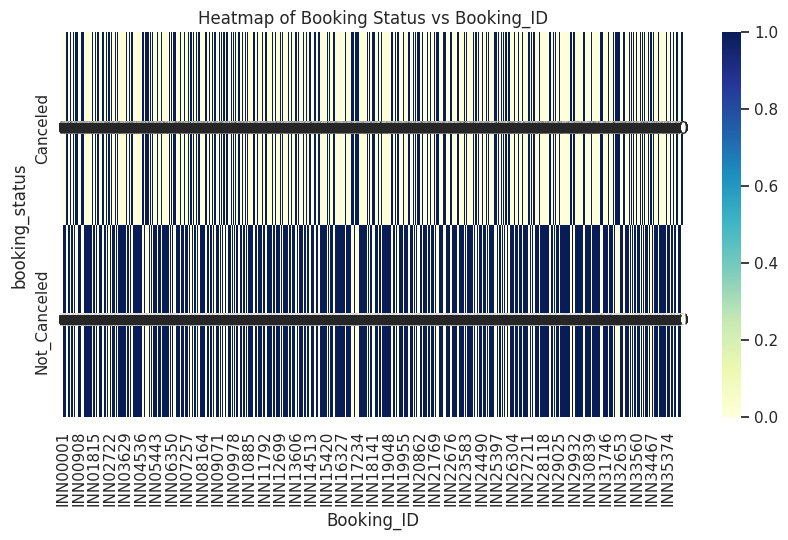

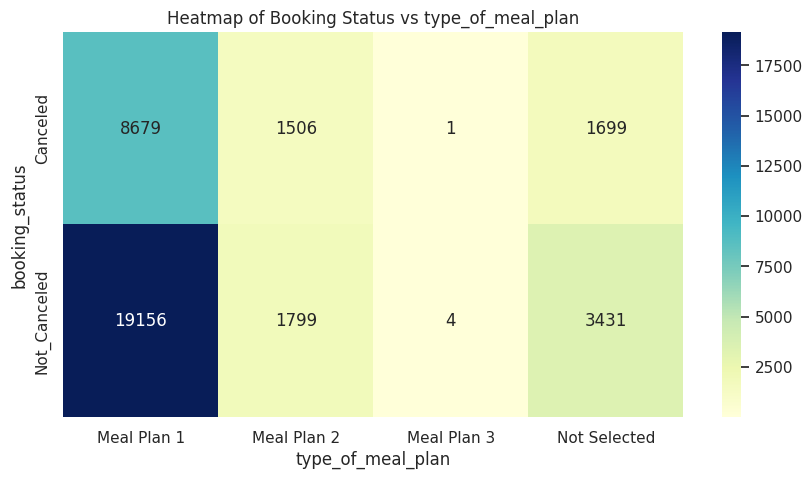

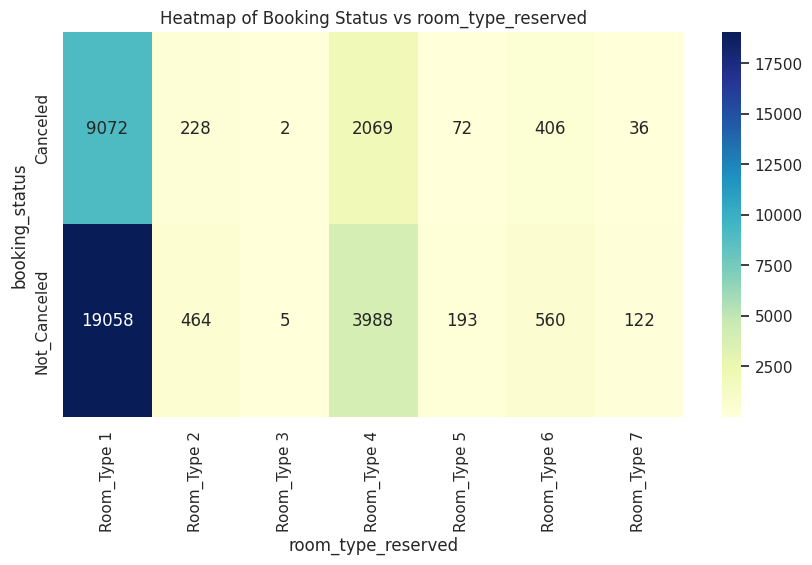

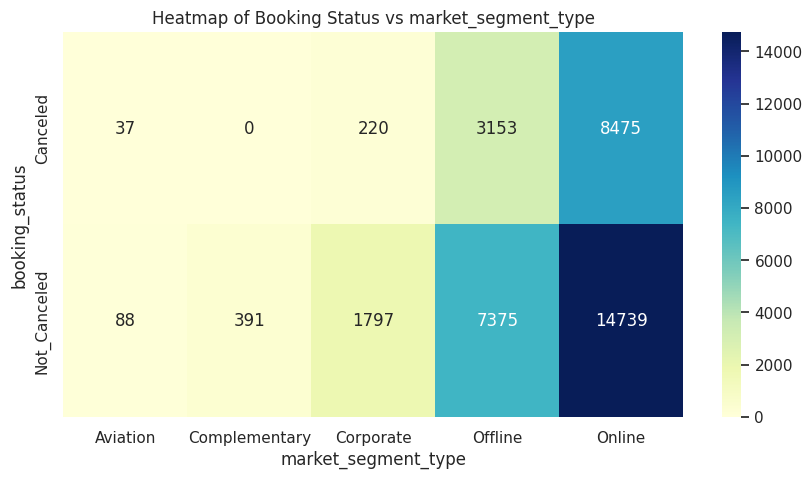

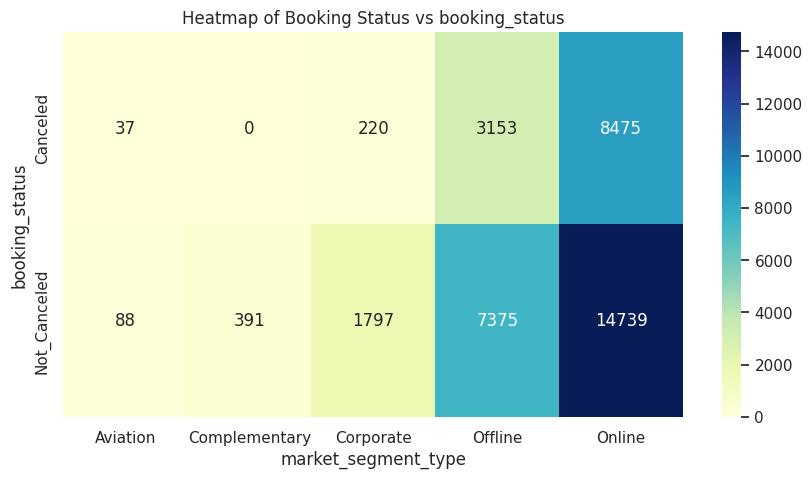

In [25]:
for col in categorical_cols:  # Create heatmaps to study categorical variables against booking_status

        if col != 'booking_status':  # Skip booking_status because comparing it with itself is not useful

         crosstab = pd.crosstab(df['booking_status'], df[col]) # Create a contingency table between booking_status and the selected categorical variable
        plt.figure(figsize=(10, 5))
        sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu') # Draw a heatmap for the contingency table
        plt.title(f"Heatmap of Booking Status vs {col}")
        plt.show()


##Percentage-Based Crosstab for Better Interpretation

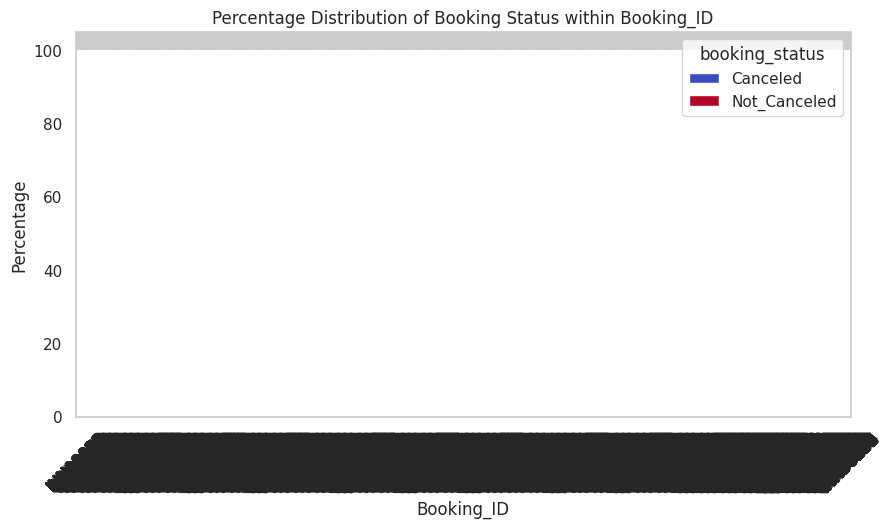

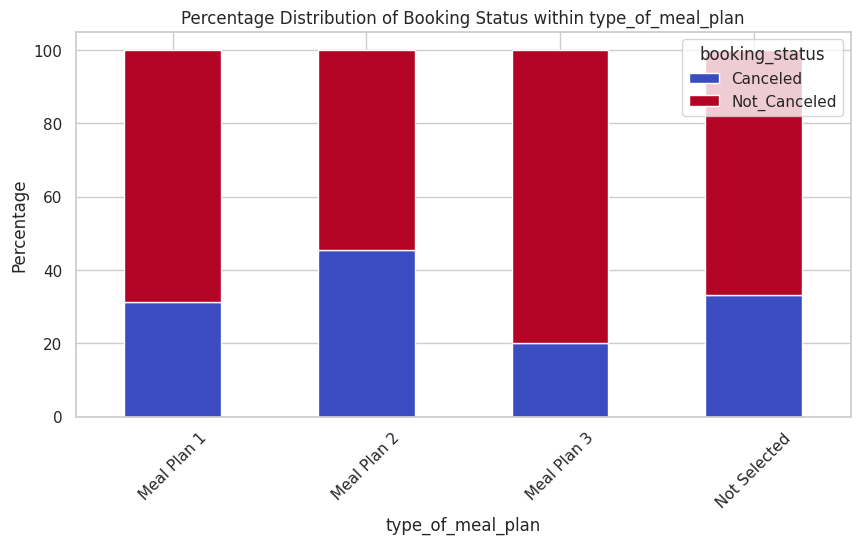

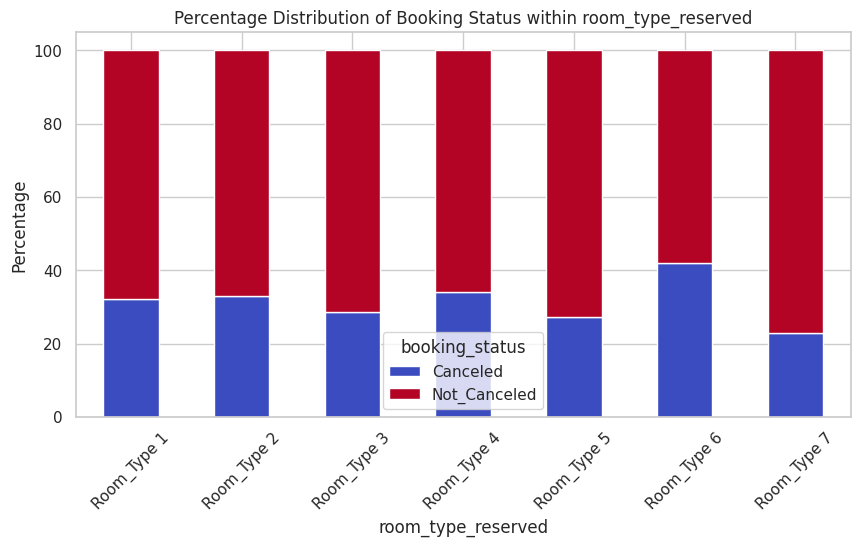

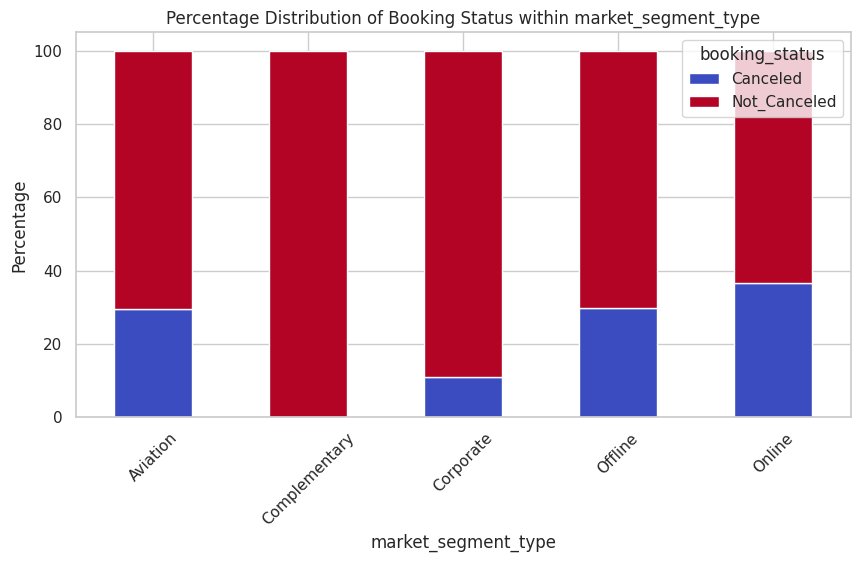

In [21]:
for col in categorical_cols:  # Create percentage crosstabs for each categorical feature against booking_status

        if col != 'booking_status':  # Skip booking_status because it is the target itself

           crosstab_percent = pd.crosstab(df[col], df['booking_status'], normalize='index') * 100  # Create a normalized crosstab to show row-wise percentage distribution

           crosstab_percent.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='coolwarm')  # Create a stacked bar plot

           plt.title(f"Percentage Distribution of Booking Status within {col}")

           plt.xlabel(col)
           plt.ylabel("Percentage")
           plt.xticks(rotation=45)  # Rotate x-axis labels
           plt.show()


**Insights**

Count plots show totals.

Percentage plots show cancellation rates within each category.

This is often more meaningful for business recommendations.

##Bivariate Analysis: Numerical vs Numerical Using Scatter Plots

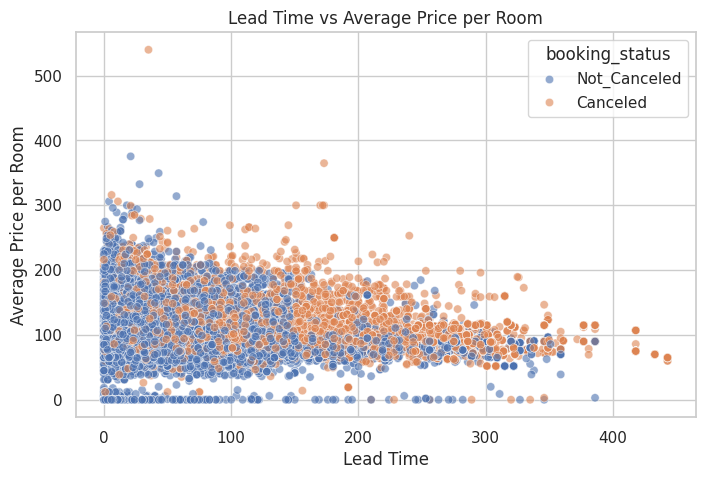

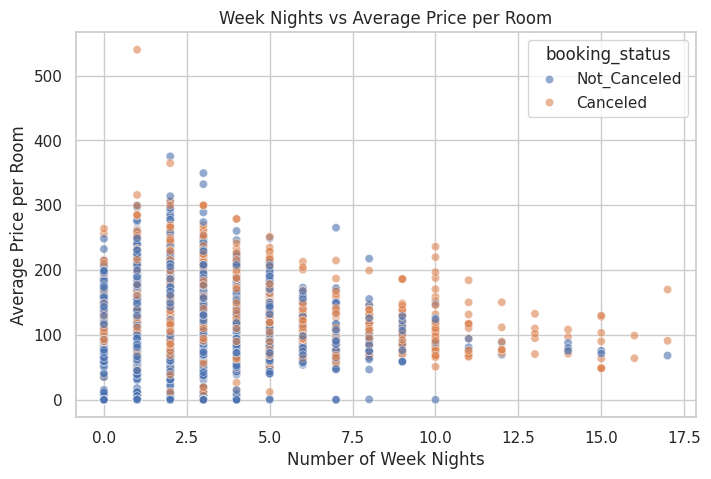

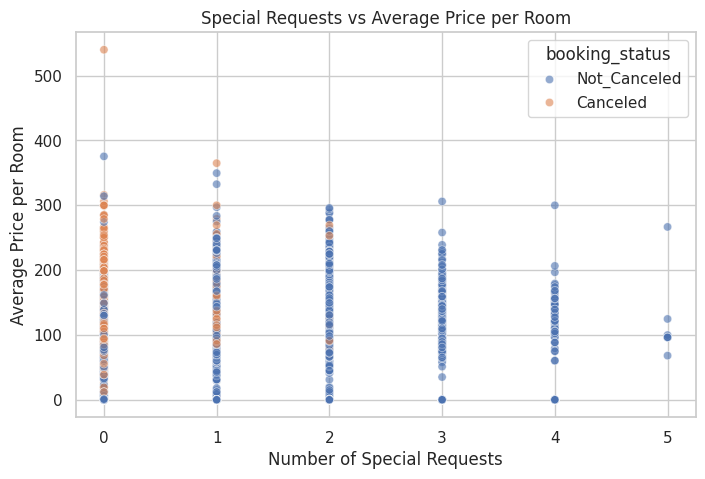

In [26]:
plt.figure(figsize=(8, 5))  # Create a scatter plot between lead_time and avg_price_per_room
sns.scatterplot(data=df, x='lead_time', y='avg_price_per_room', hue='booking_status', alpha=0.6)
plt.title("Lead Time vs Average Price per Room")
plt.xlabel("Lead Time")
plt.ylabel("Average Price per Room")
plt.show()


plt.figure(figsize=(8, 5))  # Create a scatter plot between no_of_week_nights and avg_price_per_room
sns.scatterplot(data=df, x='no_of_week_nights', y='avg_price_per_room', hue='booking_status', alpha=0.6)
plt.title("Week Nights vs Average Price per Room")
plt.xlabel("Number of Week Nights")
plt.ylabel("Average Price per Room")
plt.show()


plt.figure(figsize=(8, 5))  # Create a scatter plot between no_of_special_requests and avg_price_per_room
sns.scatterplot(data=df, x='no_of_special_requests', y='avg_price_per_room', hue='booking_status', alpha=0.6)
plt.title("Special Requests vs Average Price per Room")
plt.xlabel("Number of Special Requests")
plt.ylabel("Average Price per Room")
plt.show()


**Insights**

Whether there is clustering of canceled vs not canceled bookings.

Whether high prices or long lead times align with more cancellations.

Whether relationships are linear or weak.

##Correlation Analysis for Numerical Features

                                      no_of_adults  no_of_children  \
no_of_adults                              1.000000       -0.019787   
no_of_children                           -0.019787        1.000000   
no_of_weekend_nights                      0.103316        0.029478   
no_of_week_nights                         0.105622        0.024398   
required_car_parking_space                0.011429        0.034244   
lead_time                                 0.097287       -0.047091   
arrival_year                              0.076719        0.045983   
arrival_month                             0.021841       -0.003076   
arrival_date                              0.026338        0.025482   
repeated_guest                           -0.192277       -0.036348   
no_of_previous_cancellations             -0.047426       -0.016390   
no_of_previous_bookings_not_canceled     -0.119166       -0.021189   
avg_price_per_room                        0.296886        0.337728   
no_of_special_reques

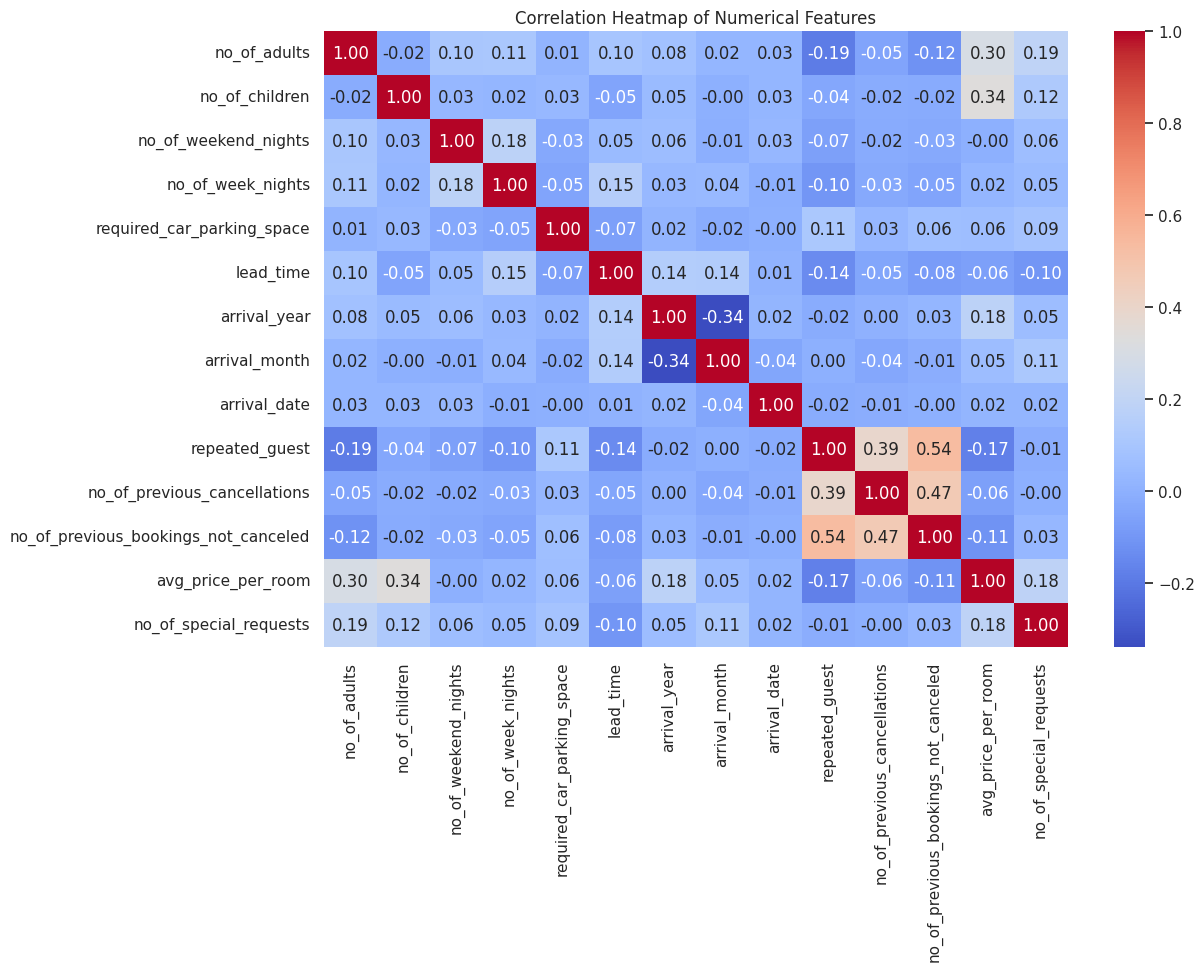

In [27]:
corr_matrix = df[numerical_cols].corr()  # Calculate the correlation matrix for numerical features
print(corr_matrix)  # Display the correlation matrix
plt.figure(figsize=(12, 8))  # Plot the correlation heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

##Pairplot for Quick Overall Pattern Checking

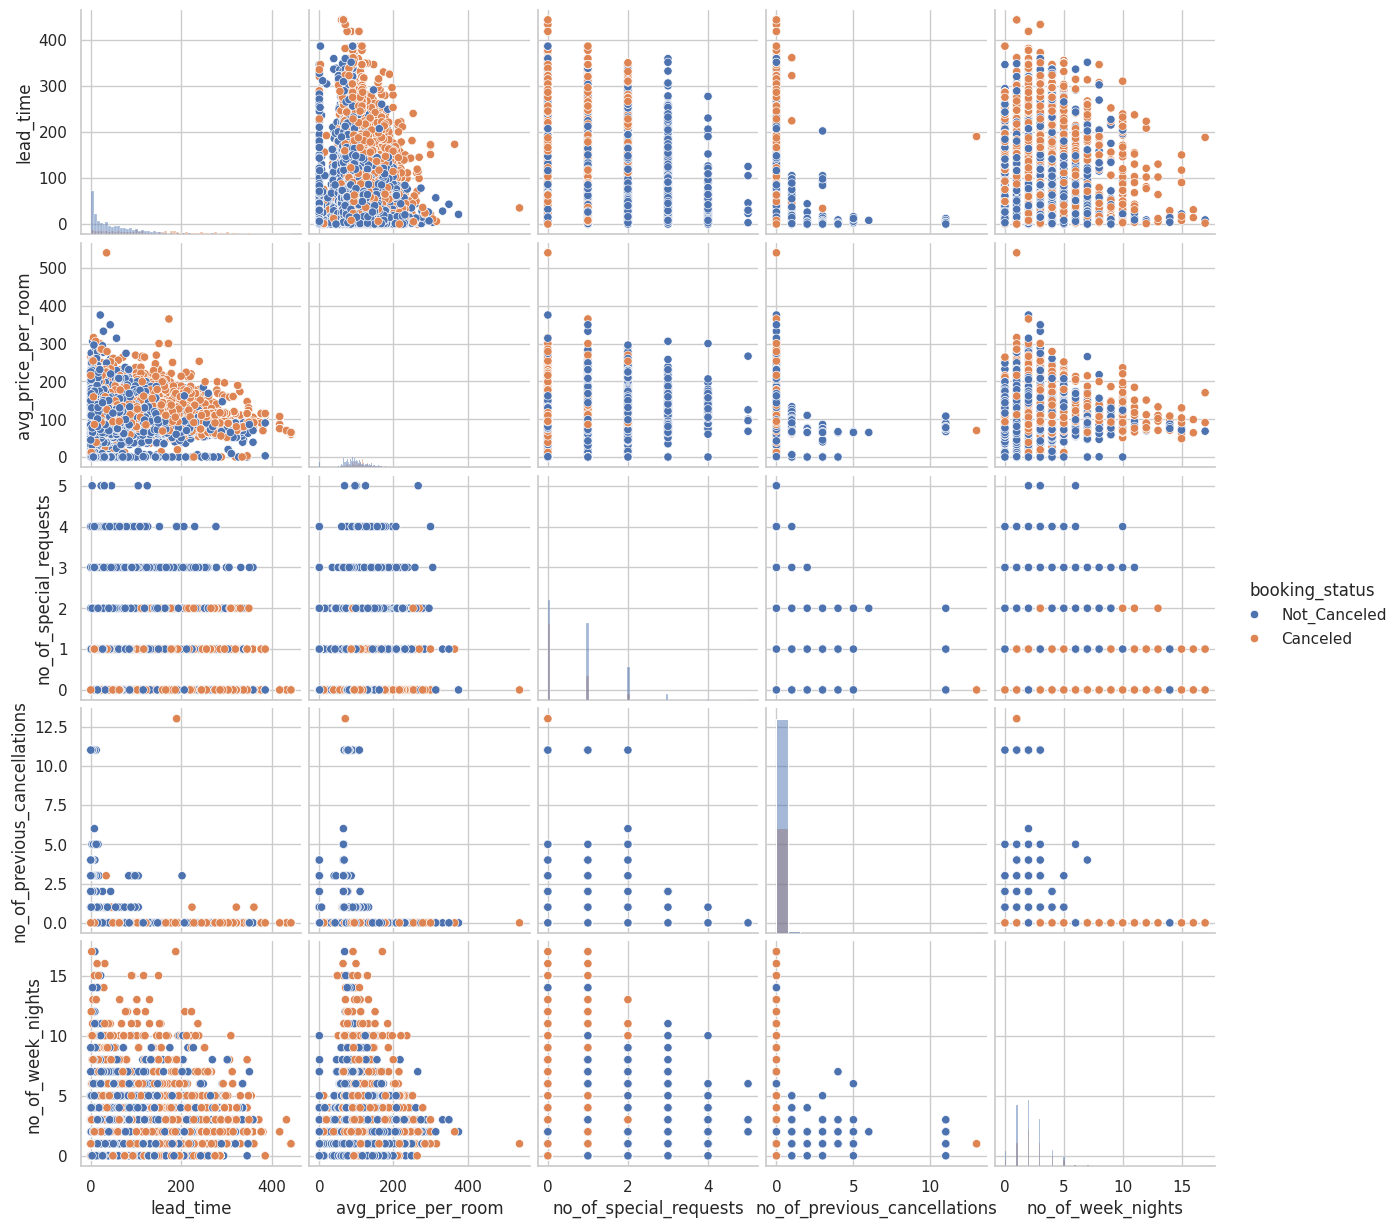

In [28]:
selected_cols = [       # Select a few important numerical columns for pairplot
    'lead_time',
    'avg_price_per_room',
    'no_of_special_requests',
    'no_of_previous_cancellations',
    'no_of_week_nights',
    'booking_status'
]

sns.pairplot(df[selected_cols], hue='booking_status', diag_kind='hist')  # Create a pairplot to study relationships among selected features
plt.show()

##Key EDA Observations

**Univariate Analysis Observations**

The dataset is complete, which makes the analysis more reliable.

Lead time and average price per room are two examples of numerical features that are likely to have skewed distributions.

Some numerical features, like price and booking lead time, may have outliers.

Market_segment_type, room_type_reserved, and type_of_meal_plan are all examples of categorical variables that show how bookings are spread out among different types of customers.

**Bivariate Analysis Observations**

You should look closely at booking_status along with lead_time, avg_price_per_room, special_requests, and past cancellations.

Boxplots can help you see if cancelled bookings tend to have longer lead times or different price ranges.

Countplots and heatmaps can help you figure out which groups of customers or types of rooms are more likely to cancel.

Scatter plots are useful for looking at how continuous variables are related and whether cancelled bookings make clusters that are easy to see.

##Answers to EDA questions

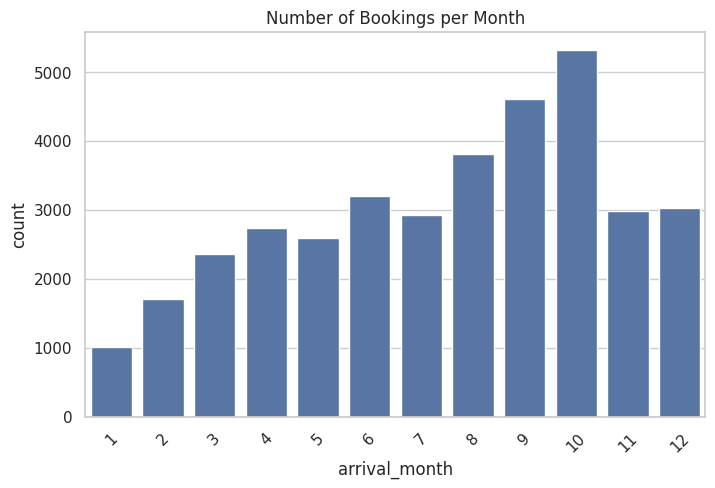

In [22]:
# What are the busiest months in the hotel?
## Count of bookings by month
plt.figure(figsize=(8,5))
sns.countplot(x='arrival_month', data=df)
plt.title("Number of Bookings per Month")
plt.xticks(rotation=45)
plt.show()

**Insights**

This shows seasonal demand patterns that are probably affected by holidays, vacations, or good travel conditions.

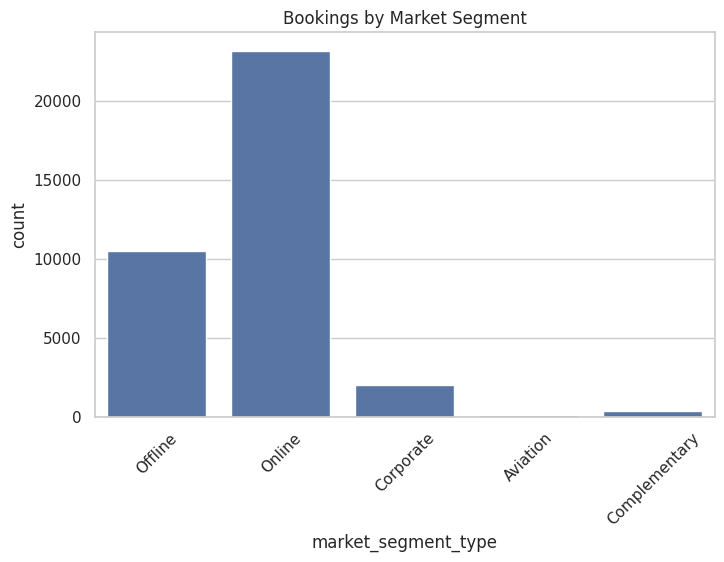

In [23]:
# Which market segment do most of the guests come from?

## Count of bookings by market segment
plt.figure(figsize=(8,5))
sns.countplot(x='market_segment_type', data=df)
plt.xticks(rotation=45)
plt.title("Bookings by Market Segment")
plt.show()

**Insights**

This shows that the hotel relies heavily on a certain group of customers to make reservations, which is a sign of customer concentration risk.

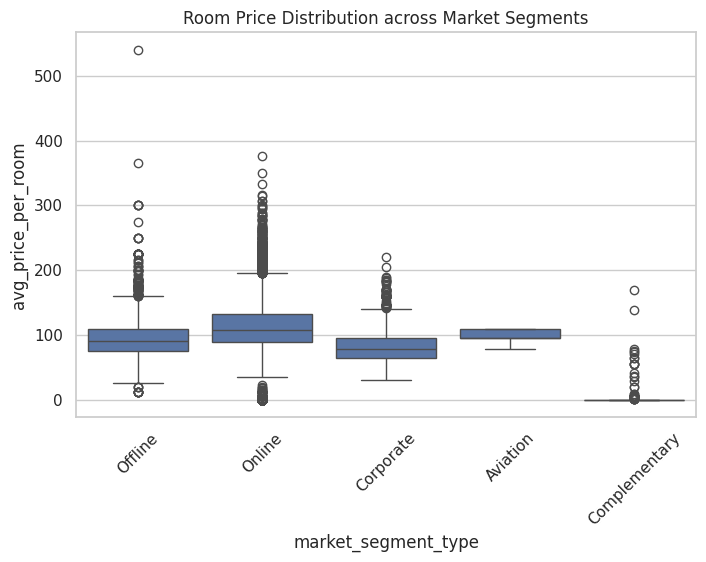

In [29]:
# Hotel rates are dynamic and change according to demand and customer demographics. What are the differences in room prices in different market segments?

## Price distribution by segment
plt.figure(figsize=(8,5))
sns.boxplot(x='market_segment_type', y='avg_price_per_room', data=df)
plt.xticks(rotation=45)
plt.title("Room Price Distribution across Market Segments")
plt.show()

**Insights**

Premium segments contribute more to revenue

Budget segments may have higher cancellation tendencies

In [30]:
# What percentage of bookings are canceled?

## Cancellation percentage
# Calculate the percentage of 'Canceled' bookings
cancel_percentage = (df['booking_status'].value_counts(normalize=True).get('Canceled', 0)) * 100
print(cancel_percentage)

32.76361130254997


**Insights**

A high cancellation rate indicates a significant revenue leakage problem and inefficiencies in booking management.

In [31]:
# Repeating guests are the guests who stay in the hotel often and are important to brand equity. What percentage of repeating guests cancel?

## Cancellation rate for repeated guests
# Convert 'booking_status' to numerical values: 1 for 'Canceled', 0 for 'Not_Canceled'
df['booking_status_encoded'] = df['booking_status'].map({'Canceled': 1, 'Not_Canceled': 0})

# Calculate the mean of the encoded booking status for each 'repeated_guest' group
repeat_cancel = df.groupby('repeated_guest')['booking_status_encoded'].mean() * 100
print(repeat_cancel)

repeated_guest
0    33.580422
1     1.720430
Name: booking_status_encoded, dtype: float64


**Insights**

Repeat customers demonstrate higher loyalty and reliability, making them valuable to the business.

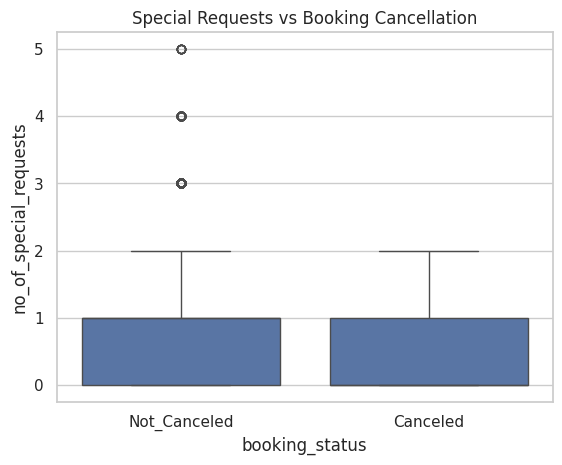

In [32]:
# Many guests have special requirements when booking a hotel room. Do these requirements affect booking cancellation?

## Special requests vs cancellation
sns.boxplot(x='booking_status', y='no_of_special_requests', data=df)
plt.title("Special Requests vs Booking Cancellation")
plt.show()

#Data Preprocessing

##Missing Value Treatment

In [33]:
missing_values = df.isnull().sum()  ## Calculate the number of missing values in each column

missing_percentage = (df.isnull().sum() / len(df)) * 100 ## Calculate the percentage of missing values in each column

missing_summary = pd.DataFrame({ # Combine missing count and missing percentage into one table for better readability
    'Missing_Count': missing_values,
    'Missing_Percentage': missing_percentage
})

print("Missing Value Summary:") # Display the missing value summary table
print(missing_summary)

Missing Value Summary:
                                      Missing_Count  Missing_Percentage
Booking_ID                                        0                 0.0
no_of_adults                                      0                 0.0
no_of_children                                    0                 0.0
no_of_weekend_nights                              0                 0.0
no_of_week_nights                                 0                 0.0
type_of_meal_plan                                 0                 0.0
required_car_parking_space                        0                 0.0
room_type_reserved                                0                 0.0
lead_time                                         0                 0.0
arrival_year                                      0                 0.0
arrival_month                                     0                 0.0
arrival_date                                      0                 0.0
market_segment_type                      

In [42]:
df_missing_treated = df.copy()  # Create a copy of the dataset for safe preprocessing

for col in df_missing_treated.columns: # Loop through each column in the dataset

        if df_missing_treated[col].dtype in ['int64', 'float64']:  # Check if the column is numerical

           df_missing_treated[col] = df_missing_treated[col].fillna(df_missing_treated[col].median())  # Fill missing numerical values with the median,Median is preferred over mean when outliers may be present

        else:  # Check if the column is categorical

           df_missing_treated[col] = df_missing_treated[col].fillna(df_missing_treated[col].mode()[0]) # Fill missing categorical values with the mode, Mode represents the most frequent category


**Rationale**

Since dataset has 0 missing values, no imputation is actually needed.

If missing values had been present:

median would be suitable for numerical columns because it is less affected by outliers.

mode would be suitable for categorical columns.

##Remove Unnecessary Columns

In [43]:
df_clean = df.copy()  # Create a copy of the original dataset before making preprocessing changes
df_clean = df_clean.drop('Booking_ID', axis=1) # Drop Booking_ID because it is only a unique identifier,It does not carry predictive business meaning for cancellation modeling
df_clean.head()  # Display the first 5 rows after dropping the identifier column

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status,booking_status_encoded
0,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled,0
1,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled,0
2,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled,1
3,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled,1
4,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled,1


**Rationale**

Booking_ID is just an identifier.

It does not help the model learn meaningful booking behavior.

Keeping it can introduce noise.

##Outlier Detection

Numerical columns:
['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'required_car_parking_space', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests', 'booking_status_encoded']


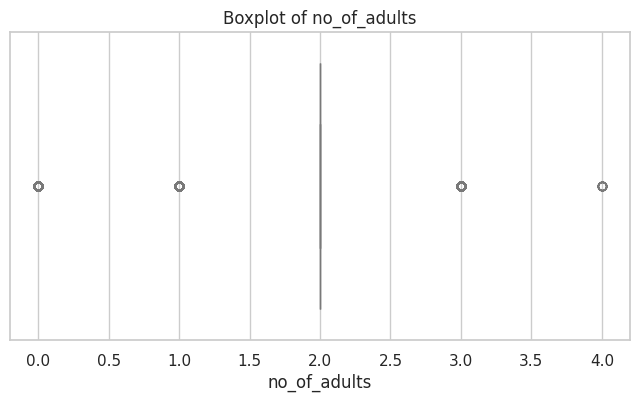

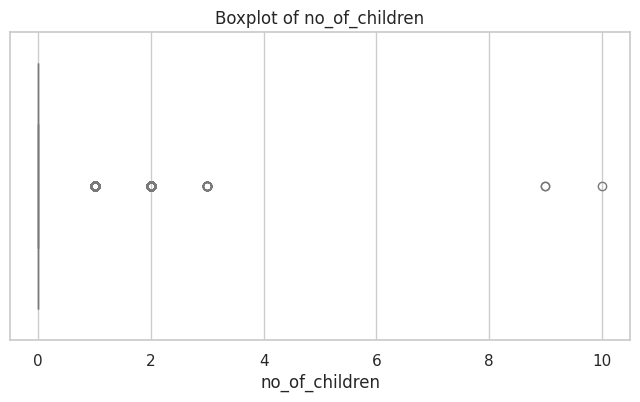

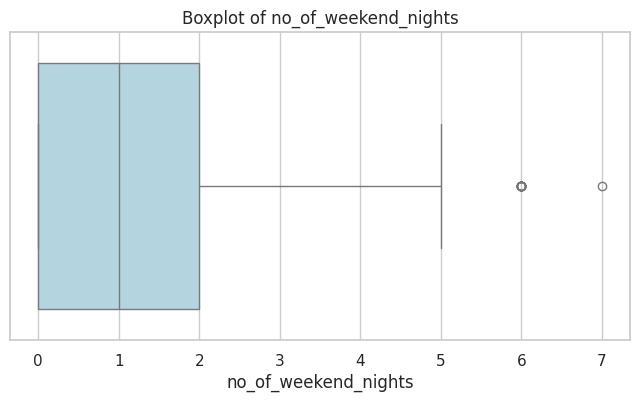

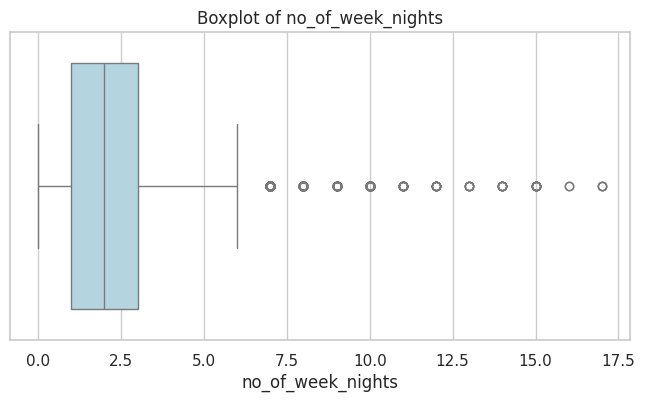

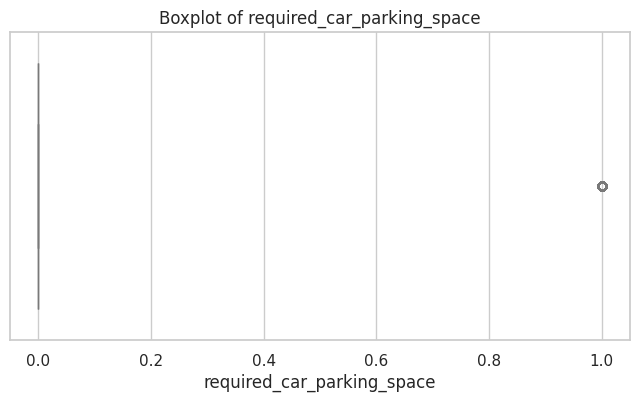

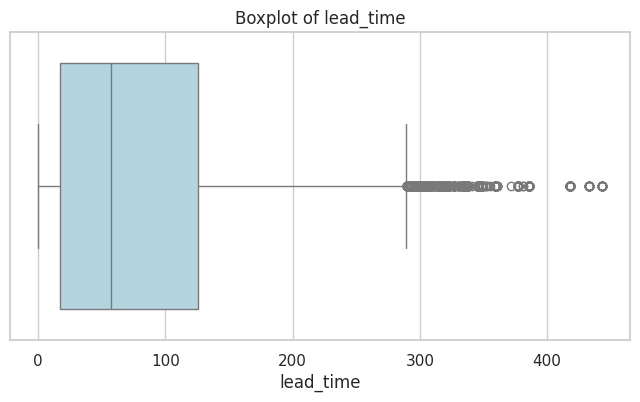

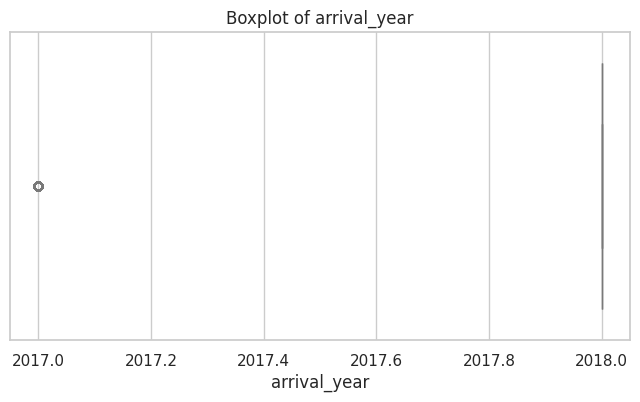

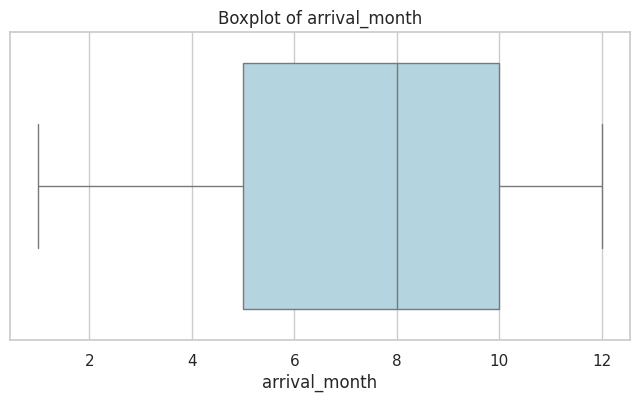

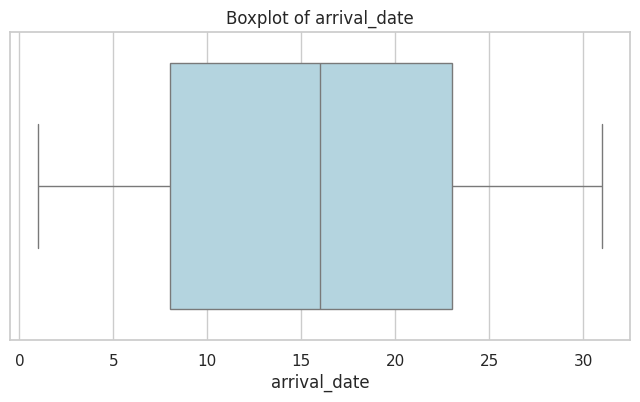

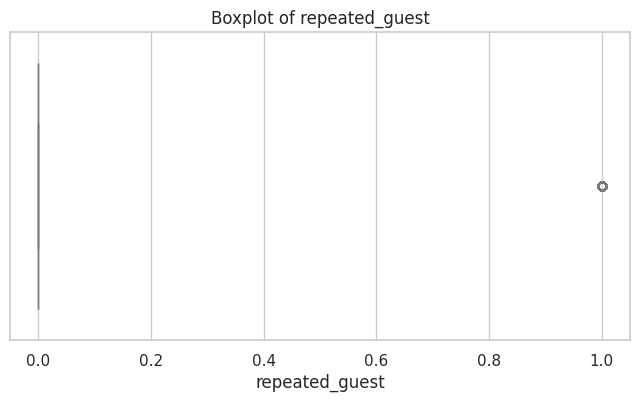

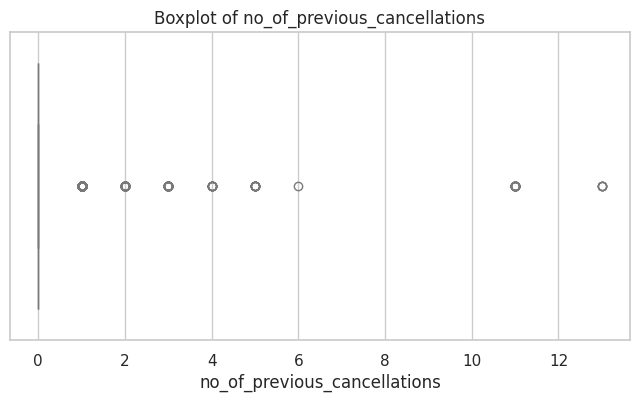

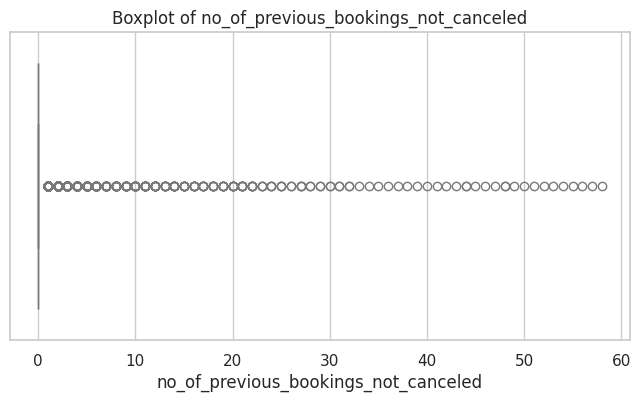

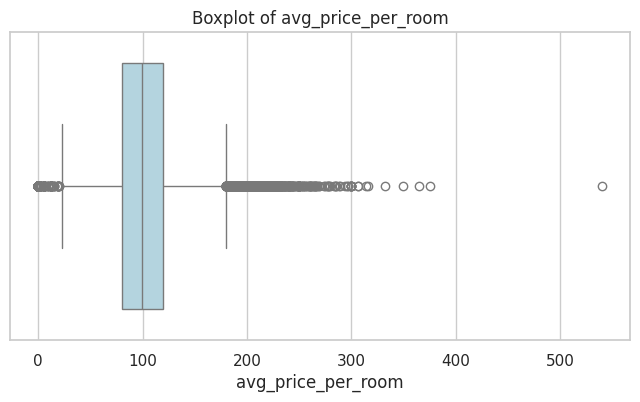

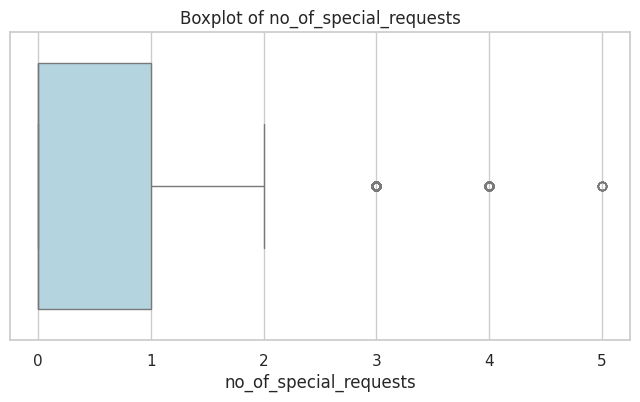

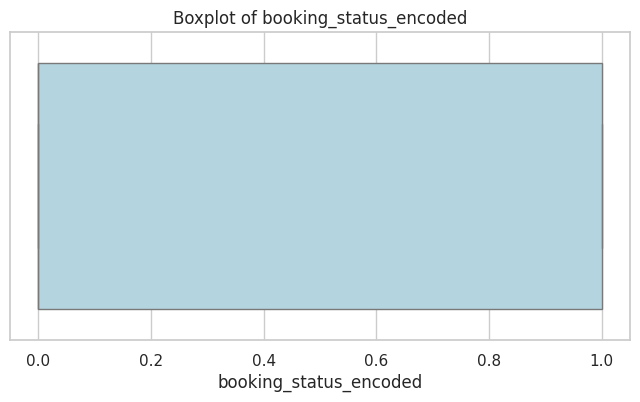

                   Column  Outlier_Count
0  booking_status_encoded              0


In [44]:
numerical_cols = df_clean.select_dtypes(include=np.number).columns.tolist() # Select only numerical columns from the cleaned dataset
print("Numerical columns:")  # Display the numerical columns
print(numerical_cols)
for col in numerical_cols:  # Create boxplots for each numerical column to visually inspect outliers
            plt.figure(figsize=(8, 4)) # Create a new figure for each numerical column
            sns.boxplot(x=df_clean[col], color='lightblue')  # Draw the boxplot for the current column
            plt.title(f"Boxplot of {col}")  # Set the title of the plot
            plt.show() # Show the plot


outlier_summary = {}  # Create an empty dictionary to store outlier counts for each numerical column

for col in numerical_cols:

        Q1 = df_clean[col].quantile(0.25)  # Calculate the first quartile (25th percentile)

        Q3 = df_clean[col].quantile(0.75)  # Calculate the third quartile (75th percentile)

        IQR = Q3 - Q1 # Calculate the Interquartile Range

        lower_bound = Q1 - 1.5 * IQR # Define the lower bound for outliers

        upper_bound = Q3 + 1.5 * IQR # Define the upper bound for outliers

        outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)].shape[0] # Count the number of outliers outside the lower and upper bounds

outlier_summary[col] = outliers  # Store the outlier count in the dictionary

outlier_summary_df = pd.DataFrame(  # Convert the dictionary to a DataFrame for better readability
    outlier_summary.items(),
    columns=['Column', 'Outlier_Count']
)
print(outlier_summary_df) # Display the outlier summary



##Outlier Treatment

In [45]:
#Winsorization / IQR Capping
df_outlier_treated = df_clean.copy() # Create a copy of the cleaned dataset for outlier treatment

for col in numerical_cols: # Loop through each numerical column to cap outliers

        Q1 = df_outlier_treated[col].quantile(0.25) # Calculate the first quartile

        Q3 = df_outlier_treated[col].quantile(0.75)   # Calculate the third quartile

        IQR = Q3 - Q1 # Calculate the Interquartile Range

        lower_bound = Q1 - 1.5 * IQR  # Define lower bound using IQR method

        upper_bound = Q3 + 1.5 * IQR   # Define upper bound using IQR method

        df_outlier_treated[col] = np.where(  # Cap values below the lower bound to the lower bound
        df_outlier_treated[col] < lower_bound,
        lower_bound,
        df_outlier_treated[col]
    )

        df_outlier_treated[col] = np.where(  # Cap values above the upper bound to the upper bound
        df_outlier_treated[col] > upper_bound,
        upper_bound,
        df_outlier_treated[col]
    )

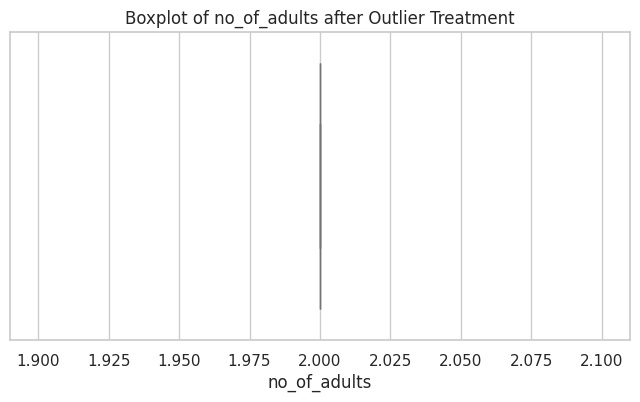

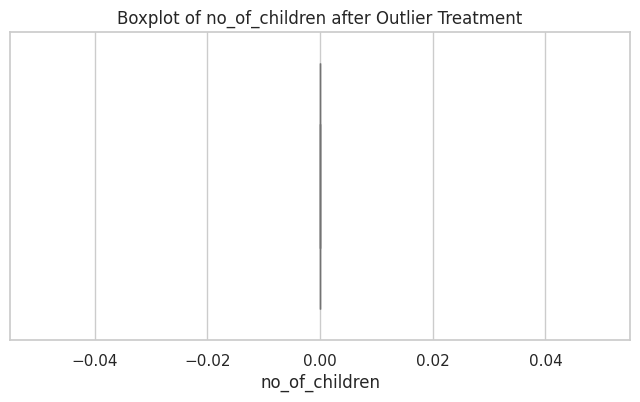

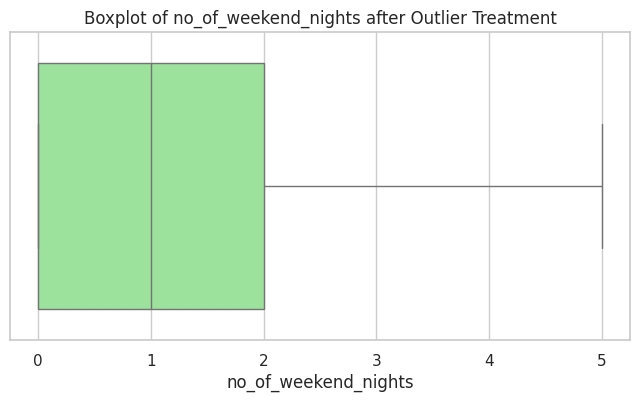

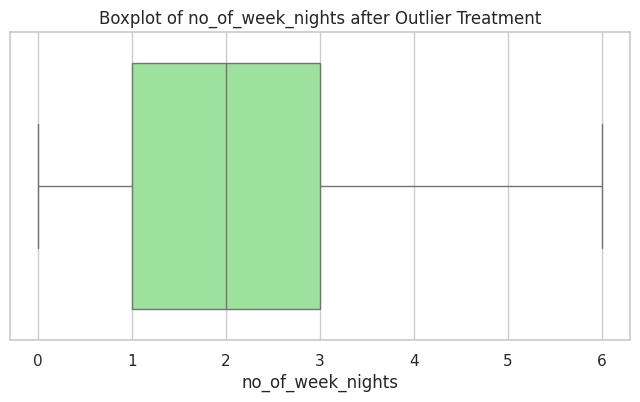

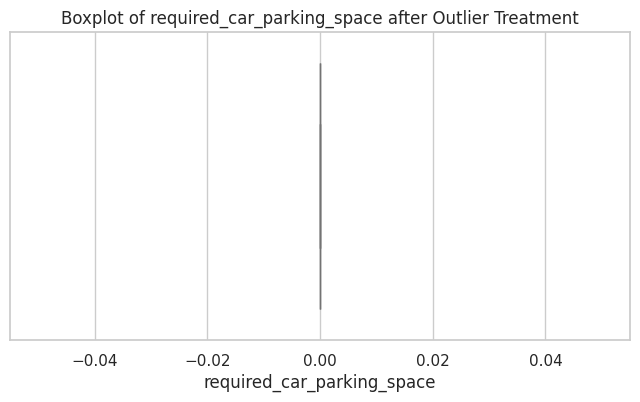

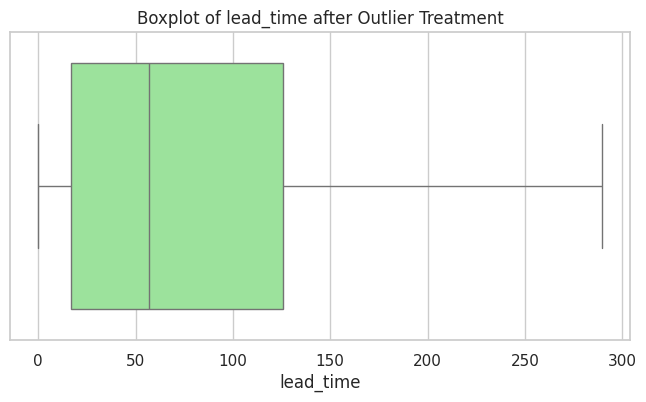

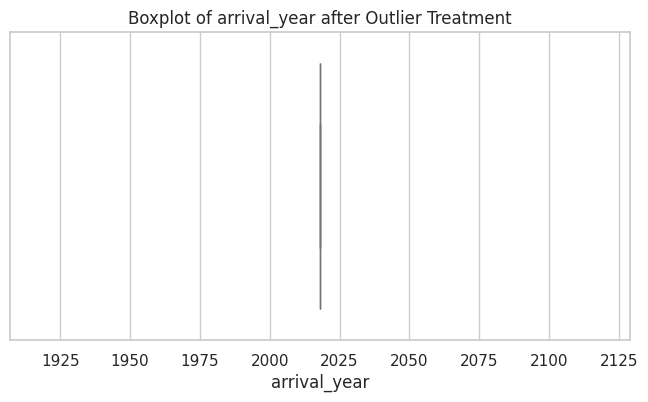

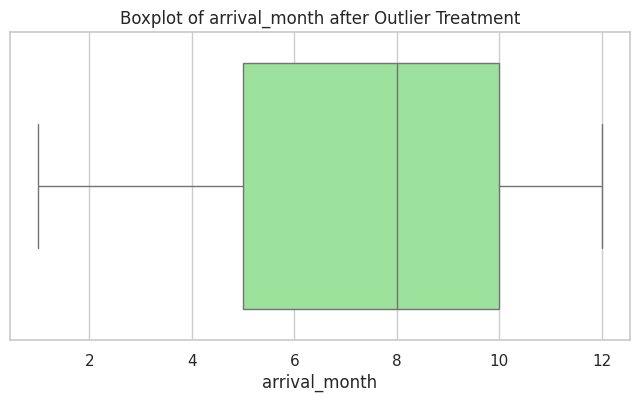

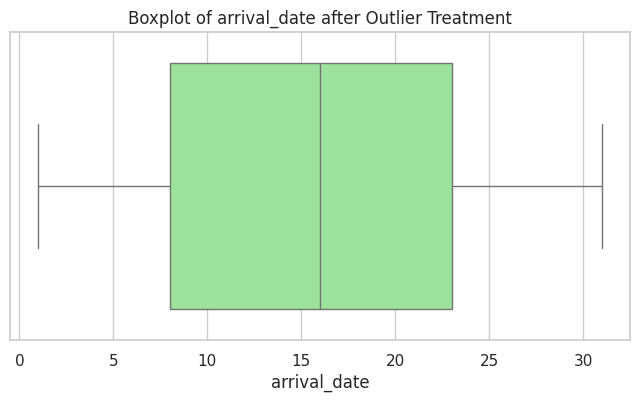

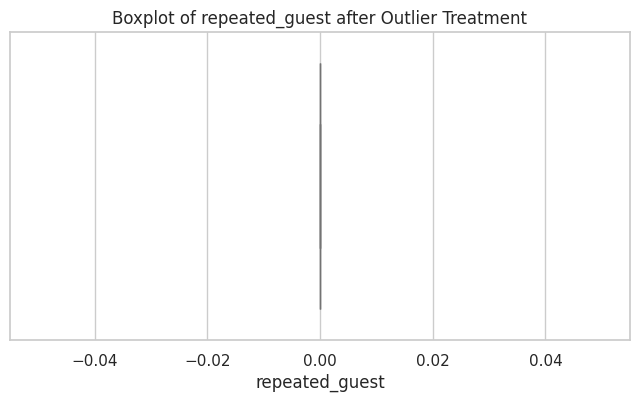

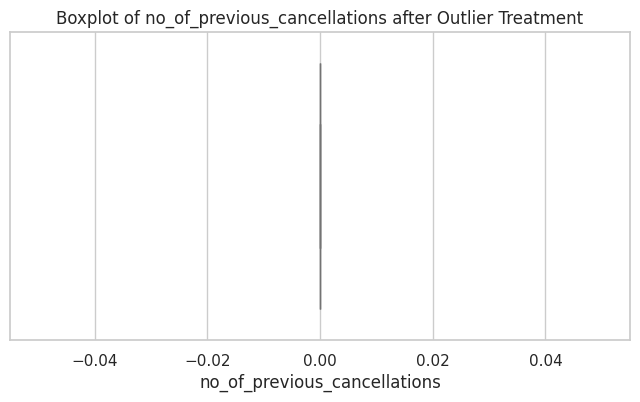

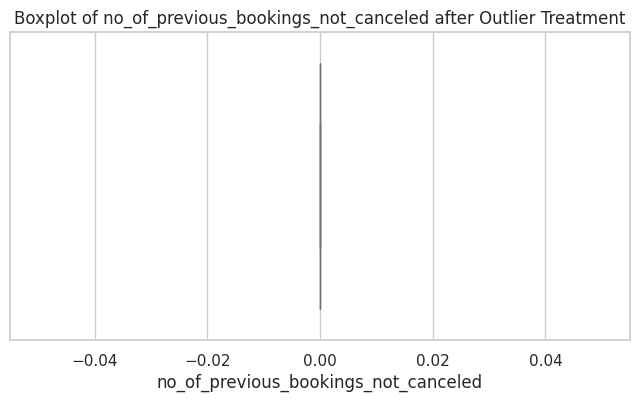

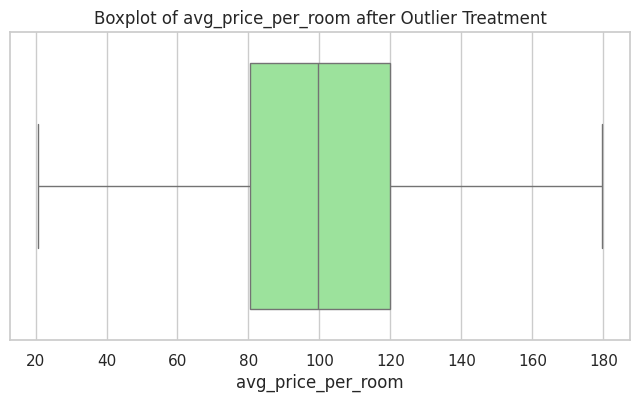

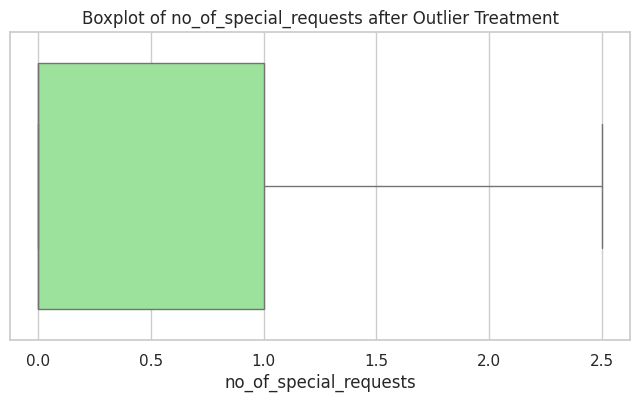

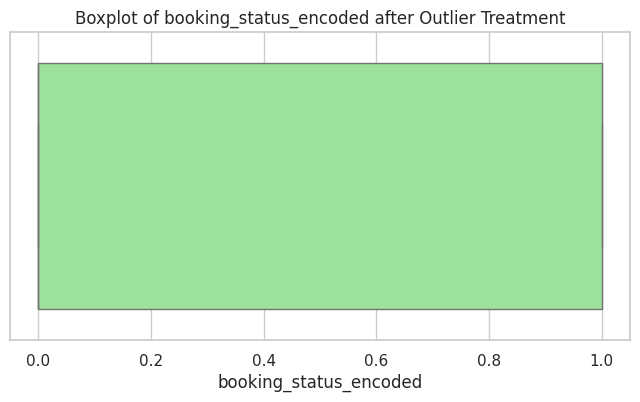

In [46]:
#Optional Recheck After Treatment

for col in numerical_cols:  # Replot boxplots after outlier treatment to visually confirm the effect

        plt.figure(figsize=(8, 4)) # Create a new figure

        sns.boxplot(x=df_outlier_treated[col], color='lightgreen') # Draw the boxplot after capping

        plt.title(f"Boxplot of {col} after Outlier Treatment") # Set plot title

        plt.show()  # Show the plot

**Rationale**

We use capping instead of row deletion because:

deleting too many rows may remove useful business cases
hotel bookings with high price or long lead time may be genuine

Capping reduces the extreme influence without throwing away data.

##Feature Engineering

In [47]:
df_featured = df_outlier_treated.copy() # Create a copy of the outlier-treated dataset for feature engineering

df_featured['total_nights'] = df_featured['no_of_weekend_nights'] + df_featured['no_of_week_nights']  # This combines weekend nights and week nights into a single stay duration variable

# Create a new feature for total guests
df_featured['total_guests'] = df_featured['no_of_adults'] + df_featured['no_of_children'] # This combines adults and children into one feature representing total group size

# Create a new feature for total previous bookings history
df_featured['total_previous_bookings'] = (  # This combines previous cancellations and previous non-canceled bookings
    df_featured['no_of_previous_cancellations'] +
    df_featured['no_of_previous_bookings_not_canceled']
)
df_featured.head()  # Display first few rows to verify new features


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,...,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status,booking_status_encoded,total_nights,total_guests,total_previous_bookings
0,2.0,0.0,1.0,2.0,Meal Plan 1,0.0,Room_Type 1,224.0,2018.0,10.0,...,0.0,0.0,0.0,65.00,0.0,Not_Canceled,0.0,3.0,2.0,0.0
1,2.0,0.0,2.0,3.0,Not Selected,0.0,Room_Type 1,5.0,2018.0,11.0,...,0.0,0.0,0.0,106.68,1.0,Not_Canceled,0.0,5.0,2.0,0.0
2,2.0,0.0,2.0,1.0,Meal Plan 1,0.0,Room_Type 1,1.0,2018.0,2.0,...,0.0,0.0,0.0,60.00,0.0,Canceled,1.0,3.0,2.0,0.0
3,2.0,0.0,0.0,2.0,Meal Plan 1,0.0,Room_Type 1,211.0,2018.0,5.0,...,0.0,0.0,0.0,100.00,0.0,Canceled,1.0,2.0,2.0,0.0
4,2.0,0.0,1.0,1.0,Not Selected,0.0,Room_Type 1,48.0,2018.0,4.0,...,0.0,0.0,0.0,94.50,0.0,Canceled,1.0,2.0,2.0,0.0


**Rationale**

total_nights gives a better idea of booking duration.

total_guests gives a better idea of booking size.

total_previous_bookings helps capture historical customer behavior.

##Encode the Target Variable

In [48]:
# Convert booking_status into numeric format
df_featured['booking_status'] = df_featured['booking_status'].map({  # Not_Canceled is encoded as 0,Canceled is encoded as 1
    'Not_Canceled': 0,
    'Canceled': 1
})
df_featured['booking_status'].head() # Check the first few rows of the target column after encoding

,booking_status
0,0
1,0
2,1
3,1
4,1


**Rationale**

Binary encoding is necessary for classification models.

0 and 1 are standard and easy to interpret.

##Encode Categorical Input Features

In [49]:
# Convert categorical input variables into numeric format using one-hot encoding.
categorical_cols = df_featured.select_dtypes(include='object').columns.tolist() # Identify categorical columns from the featured dataset
print("Categorical columns before encoding:") # Display categorical columns before encoding
print(categorical_cols)

df_encoded = pd.get_dummies(df_featured, columns=categorical_cols, drop_first=True) # Apply one-hot encoding to categorical input variables, drop_first=True helps reduce multicollinearity by dropping one dummy category
df_encoded.head() # Display the first 5 rows after encoding


Categorical columns before encoding:
['type_of_meal_plan', 'room_type_reserved', 'market_segment_type']


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
0,2.0,0.0,1.0,2.0,0.0,224.0,2018.0,10.0,2.0,0.0,...,False,False,False,False,False,False,False,False,True,False
1,2.0,0.0,2.0,3.0,0.0,5.0,2018.0,11.0,6.0,0.0,...,False,False,False,False,False,False,False,False,False,True
2,2.0,0.0,2.0,1.0,0.0,1.0,2018.0,2.0,28.0,0.0,...,False,False,False,False,False,False,False,False,False,True
3,2.0,0.0,0.0,2.0,0.0,211.0,2018.0,5.0,20.0,0.0,...,False,False,False,False,False,False,False,False,False,True
4,2.0,0.0,1.0,1.0,0.0,48.0,2018.0,4.0,11.0,0.0,...,False,False,False,False,False,False,False,False,False,True


**Rationale**

Machine learning models cannot directly use text categories.

One-hot encoding converts categories into binary indicator columns.

drop_first=True helps avoid the dummy variable trap in linear models.

##Define Features and Target

In [50]:
X = df_encoded.drop('booking_status', axis=1) # Define X as the input features by dropping the target column
y = df_encoded['booking_status'] # Define y as the target variable
print("Shape of X:", X.shape) # Display the shape of feature matrix and target vector
print("Shape of y:", y.shape)

Shape of X: (36275, 31)
Shape of y: (36275,)


##Train-Test Split

In [51]:
X_train, X_test, y_train, y_test = train_test_split(  # Split the data into training and testing sets
    X,
    y,
    test_size=0.30, # test_size=0.30 means 30% of the data will be used for testing
    random_state=42,  # random_state=42 ensures reproducibility
    stratify=y  # stratify=y maintains the class distribution in train and test sets
)
print("X_train shape:", X_train.shape) # Display the shape of the train and test sets
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (25392, 31)
X_test shape: (10883, 31)
y_train shape: (25392,)
y_test shape: (10883,)


In [52]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and fit the Decision Tree model globally
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

**Rationale**

Train-test split helps evaluate how well the model performs on unseen data.

stratify=y is important because the target classes are not perfectly balanced.

## Data Scaling

In [53]:
from sklearn.preprocessing import StandardScaler

#Scaling should be done after train-test split to avoid data leakage.

# Create a list of columns to scale
scale_cols = [  # These are numerical features where magnitude differences may affect model performance
    'no_of_adults',
    'no_of_children',
    'no_of_weekend_nights',
    'no_of_week_nights',
    'lead_time',
    'arrival_year',
    'arrival_month',
    'arrival_date',
    'no_of_previous_cancellations',
    'no_of_previous_bookings_not_canceled',
    'avg_price_per_room',
    'no_of_special_requests',
    'total_nights',
    'total_guests',
    'total_previous_bookings'
]

scaler = StandardScaler() # Create an instance of StandardScaler
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols]) # Fit the scaler only on the training data and transform the training data
X_test[scale_cols] = scaler.transform(X_test[scale_cols]) # Use the same fitted scaler to transform the testing data
X_train.head() # Display the first 5 rows of the scaled training data

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
19385,0.0,0.0,1.368630,-1.679765,0.0,-0.044425,0.0,-1.116503,-1.442368,0.0,...,False,False,False,False,False,False,False,False,False,True
12553,0.0,0.0,3.675297,2.956471,0.0,-0.988463,0.0,-0.790530,-1.671049,0.0,...,False,False,True,False,False,False,False,False,False,False
21002,0.0,0.0,0.215296,0.638353,0.0,0.347903,0.0,0.839339,-0.641982,0.0,...,False,False,False,False,False,False,False,False,True,False
32673,0.0,0.0,-0.938037,-0.134353,0.0,-0.154767,0.0,1.165312,0.272744,0.0,...,False,False,False,False,False,False,False,False,False,True
528,0.0,0.0,1.368630,-0.907059,0.0,-0.694218,0.0,-0.464556,1.187469,0.0,...,False,False,True,False,False,False,False,False,False,True


**Rationale**

Scaling is needed because some features have very different ranges.

For example:

lead_time can be in the hundreds

no_of_children is usually very small

Algorithms like Logistic Regression, KNN, and SVM perform better when features are scaled.

##Final Preprocessed Data Check

In [54]:
print("Missing values in X_train:") # Check whether there are any missing values in training data after preprocessing
print(X_train.isnull().sum().sum())

print("Missing values in X_test:")  # Check whether there are any missing values in testing data after preprocessing
print(X_test.isnull().sum().sum())

print("Final X_train shape:", X_train.shape) # Display the final shape of processed training and testing sets
print("Final X_test shape:", X_test.shape)

Missing values in X_train:
0
Missing values in X_test:
0
Final X_train shape: (25392, 31)
Final X_test shape: (10883, 31)


#Model Building

**Choose the Metric to Optimize**

Since the goal is to identify likely cancellations, recall is the most important metric.

A higher recall helps detect more actual cancellations.

However, recall should not be judged alone, so F1-score and ROC-AUC are also used to evaluate overall model quality.

In [55]:
print("X_train shape:", X_train.shape) # Print the shape of training features
print("X_test shape:", X_test.shape) # Print the shape of test features
print("y_train shape:", y_train.shape) # Print the shape of training target
print("y_test shape:", y_test.shape) # Print the shape of test target

X_train shape: (25392, 31)
X_test shape: (10883, 31)
y_train shape: (25392,)
y_test shape: (10883,)


##Logistic Regression Using statsmodels

In [56]:
# Define columns to drop based on VIF analysis (constant or perfectly multicollinear)
cols_to_drop = [
    'total_nights', # Drop engineered total_nights as its components are present
    'no_of_adults', # Constant after scaling
    'no_of_children', # Constant after scaling
    'required_car_parking_space', # Constant after scaling
    'arrival_year', # Constant after scaling
    'repeated_guest', # Constant after scaling
    'no_of_previous_cancellations', # Constant after scaling
    'no_of_previous_bookings_not_canceled', # Constant after scaling
    'total_guests', # Constant after scaling
    'total_previous_bookings' # Constant after scaling
]
X_train_filtered = X_train.drop(columns=cols_to_drop, errors='ignore') # Create filtered copies of the training and test feature sets
X_test_filtered = X_test.drop(columns=cols_to_drop, errors='ignore')

# Convert any remaining boolean columns to integer (0 or 1) for statsmodels compatibility
for col in X_train_filtered.select_dtypes(include='bool').columns:
    X_train_filtered[col] = X_train_filtered[col].astype(float) # This ensures all features are numeric, as required by statsmodels.Logit
for col in X_test_filtered.select_dtypes(include='bool').columns:
    X_test_filtered[col] = X_test_filtered[col].astype(float)
X_train_sm = sm.add_constant(X_train_filtered) # This constant acts as the intercept term in Logistic Regression,Add a constant column to the training feature set
X_test_sm = sm.add_constant(X_test_filtered) # Add a constant column to the test feature set as well
X_train_sm.head()  # Display the first 5 rows of the training data with the constant added

,const,no_of_weekend_nights,no_of_week_nights,lead_time,arrival_month,arrival_date,avg_price_per_room,no_of_special_requests,booking_status_encoded,type_of_meal_plan_Meal Plan 2,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
19385,1.0,1.368630,-1.679765,-0.044425,-1.116503,-1.442368,-0.668312,-0.815749,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
12553,1.0,3.675297,2.956471,-0.988463,-0.790530,-1.671049,0.221128,-0.815749,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21002,1.0,0.215296,0.638353,0.347903,0.839339,-0.641982,-0.704712,-0.815749,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
32673,1.0,-0.938037,-0.134353,-0.154767,1.165312,0.272744,-0.475231,-0.815749,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
528,1.0,1.368630,-0.907059,-0.694218,-0.464556,1.187469,1.571746,-0.815749,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [57]:
#Check Multicollinearity Using VIF
vif_data = pd.DataFrame() # Create an empty DataFrame to store VIF values
vif_data["Feature"] = X_train_sm.columns # Store the feature names in the DataFrame

# Calculate VIF for each feature one by one
vif_data["VIF"] = [  ## The X_train_sm dataframe should now already be numeric after modifications in Fv_oQYNBa_f8
  variance_inflation_factor(X_train_sm.values, i) # Use the numeric version of X_train_sm here
    for i in range(X_train_sm.shape[1]) # No separate conversion to X_train_sm_numeric is needed here.
]
print(vif_data.sort_values(by="VIF", ascending=False)) # Display the VIF table sorted in descending order

                              Feature         VIF
0                               const  290.696381
21         market_segment_type_Online   67.110153
20        market_segment_type_Offline   60.484812
19      market_segment_type_Corporate   16.257603
18  market_segment_type_Complementary    4.226074
6                  avg_price_per_room    1.796700
3                           lead_time    1.571350
8              booking_status_encoded    1.516082
7              no_of_special_requests    1.393493
14     room_type_reserved_Room_Type 4    1.299009
11     type_of_meal_plan_Not Selected    1.237133
16     room_type_reserved_Room_Type 6    1.218413
9       type_of_meal_plan_Meal Plan 2    1.190060
2                   no_of_week_nights    1.088525
17     room_type_reserved_Room_Type 7    1.067029
4                       arrival_month    1.052937
1                no_of_weekend_nights    1.049900
12     room_type_reserved_Room_Type 2    1.031849
15     room_type_reserved_Room_Type 5    1.024950


In [58]:
# Import statsmodels for Logistic Regression
import statsmodels.api as sm

# Import numpy for numerical operations
import numpy as np

# Create copies of training and testing feature sets
X_train_logit = X_train.copy() # This keeps the original X_train and X_test unchanged
X_test_logit = X_test.copy()

# This avoids perfect multicollinearity

cols_to_drop_for_logit = [ # Drop original columns that are exact components of engineered features
    'no_of_weekend_nights', # total_nights = no_of_weekend_nights + no_of_week_nights
    'no_of_week_nights',
    'no_of_adults', # total_guests = no_of_adults + no_of_children
    'no_of_children',
    'no_of_previous_cancellations', # total_previous_bookings = no_of_previous_cancellations + no_of_previous_bookings_not_canceled
    'no_of_previous_bookings_not_canceled'
]

X_train_logit = X_train_logit.drop(columns=cols_to_drop_for_logit, errors='ignore') # Drop those columns from training data

X_test_logit = X_test_logit.drop(columns=cols_to_drop_for_logit, errors='ignore') # Drop the same columns from test data

# Remove constant columns from the training data
constant_cols = [col for col in X_train_logit.columns if X_train_logit[col].nunique() <= 1] # Constant columns have no variation and can cause fitting issues

X_train_logit = X_train_logit.drop(columns=constant_cols, errors='ignore') # Drop constant columns from both training and test data
X_test_logit = X_test_logit.drop(columns=constant_cols, errors='ignore')

# Remove duplicate columns if any exist
duplicate_cols = X_train_logit.T[X_train_logit.T.duplicated()].index.tolist() # Sometimes two columns can become exactly identical after encoding/splitting

# Drop duplicate columns from both training and test data
X_train_logit = X_train_logit.drop(columns=duplicate_cols, errors='ignore')
X_test_logit = X_test_logit.drop(columns=duplicate_cols, errors='ignore')

# Convert all columns to float to ensure statsmodels receives purely numeric input
X_train_logit = X_train_logit.astype(float)
X_test_logit = X_test_logit.astype(float)

# Convert target variables to integer type
y_train_logit = y_train.astype(int)
y_test_logit = y_test.astype(int)

# Add the intercept term to both train and test data
X_train_sm = sm.add_constant(X_train_logit, has_constant='add')
X_test_sm = sm.add_constant(X_test_logit, has_constant='add')

# Print the final shape of the training data used for Logistic Regression
print("Final X_train shape for Logistic Regression:", X_train_sm.shape)

# Print matrix rank information
# If rank is less than the number of columns, the matrix is still singular
print("Matrix rank:", np.linalg.matrix_rank(X_train_sm))
print("Number of columns:", X_train_sm.shape[1])

# Fit the Logistic Regression model using regularized fitting
# This is more stable than plain fit() when the data has near-collinearity
# method='l1' applies L1 regularization

logit_model = sm.Logit(y_train_logit, X_train_sm)
logit_result = logit_model.fit_regularized(method='l1', alpha=0.0001, disp=False) # alpha is kept very small so the model remains close to standard logistic regression

# Print the fitted model parameters
print("Logistic Regression model fitted successfully.")
print(logit_result.params)

Final X_train shape for Logistic Regression: (25392, 21)
Matrix rank: 21
Number of columns: 21
Logistic Regression model fitted successfully.
const                               -23.139754
lead_time                             2.011707
arrival_month                        -1.424260
arrival_date                          0.375066
avg_price_per_room                    0.002382
no_of_special_requests               -1.396557
booking_status_encoded               51.881507
total_nights                          1.377557
type_of_meal_plan_Meal Plan 2        -1.909373
type_of_meal_plan_Meal Plan 3        -0.004920
type_of_meal_plan_Not Selected        0.238873
room_type_reserved_Room_Type 2       -0.389601
room_type_reserved_Room_Type 3        0.001867
room_type_reserved_Room_Type 4       -3.271012
room_type_reserved_Room_Type 5       -0.414409
room_type_reserved_Room_Type 6       -0.977824
room_type_reserved_Room_Type 7       -0.236366
market_segment_type_Complementary    -0.836326
market_segme

/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 12 out of 21 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)


In [59]:
# Predict probabilities for the test set
y_prob_logit = logit_result.predict(X_test_sm)

# Convert probabilities into predicted class labels using 0.5 threshold
y_pred_logit = (y_prob_logit >= 0.5).astype(int)

# Display first few predicted probabilities
print("First 10 predicted probabilities:")
print(y_prob_logit[:10])

# Display first few predicted class labels
print("First 10 predicted classes:")
print(y_pred_logit[:10])

First 10 predicted probabilities:
32030    1.000000e+00
17420    2.045845e-16
29693    6.486606e-18
30826    3.841485e-12
28087    1.000000e+00
8516     1.000000e+00
6449     1.000000e+00
11426    7.144276e-12
29860    8.009040e-11
11325    1.000000e+00
dtype: float64
First 10 predicted classes:
32030    1
17420    0
29693    0
30826    0
28087    1
8516     1
6449     1
11426    0
29860    0
11325    1
dtype: int64


In [60]:
# Predict Using Logistic Regression

# Predict the probability of cancellation for the test set
y_prob_logit = logit_result.predict(X_test_sm) # These are probabilities between 0 and 1

# Convert predicted probabilities into predicted class labels
y_pred_logit = (y_prob_logit >= 0.5).astype(int) # If probability is greater than or equal to 0.5, classify as Canceled (1),Otherwise classify as Not_Canceled (0)

print("First 10 predicted probabilities from Logistic Regression:")
print(y_prob_logit[:10]) # Display the first 10 predicted probabilities

print("First 10 predicted classes from Logistic Regression:")
print(y_pred_logit[:10]) # Display the first 10 predicted classes

First 10 predicted probabilities from Logistic Regression:
32030    1.000000e+00
17420    2.045845e-16
29693    6.486606e-18
30826    3.841485e-12
28087    1.000000e+00
8516     1.000000e+00
6449     1.000000e+00
11426    7.144276e-12
29860    8.009040e-11
11325    1.000000e+00
dtype: float64
First 10 predicted classes from Logistic Regression:
32030    1
17420    0
29693    0
30826    0
28087    1
8516     1
6449     1
11426    0
29860    0
11325    1
dtype: int64


### Evaluate Logistic Regression Model

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_logit = accuracy_score(y_test, y_pred_logit) # Calculate accuracy for Logistic Regression

precision_logit = precision_score(y_test, y_pred_logit) # Calculate precision for Logistic Regression

recall_logit = recall_score(y_test, y_pred_logit) # Calculate recall for Logistic Regression

f1_logit = f1_score(y_test, y_pred_logit) # Calculate F1-score for Logistic Regression

roc_auc_logit = roc_auc_score(y_test, y_prob_logit) # Calculate ROC-AUC score for Logistic Regression using predicted probabilities

# Print all evaluation metrics
print("Logistic Regression Performance:")
print("Accuracy :", accuracy_logit)
print("Precision:", precision_logit)
print("Recall   :", recall_logit)
print("F1 Score :", f1_logit)
print("ROC-AUC  :", roc_auc_logit)

Logistic Regression Performance:
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [62]:
from sklearn.metrics import classification_report

# Classification Report for Logistic Regression
print("Classification Report for Logistic Regression:") # This gives precision, recall, f1-score, and support for each class
print(classification_report(y_test, y_pred_logit)) # Print classification report for Logistic Regression

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7317
           1       1.00      1.00      1.00      3566

    accuracy                           1.00     10883
   macro avg       1.00      1.00      1.00     10883
weighted avg       1.00      1.00      1.00     10883



Confusion Matrix for Logistic Regression:
[[7317    0]
 [   0 3566]]


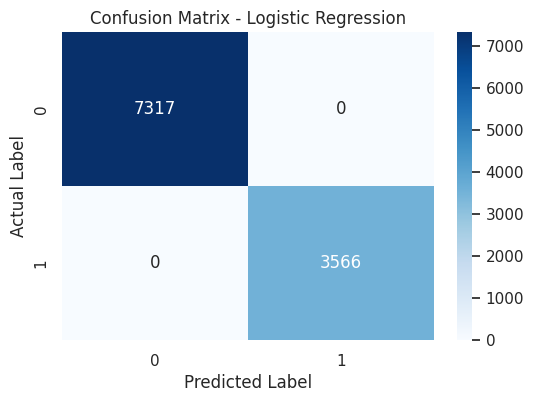

In [63]:
# Confusion Matrix for Logistic Regression

cm_logit = confusion_matrix(y_test, y_pred_logit) # Generate confusion matrix for Logistic Regression
print("Confusion Matrix for Logistic Regression:") # Print the confusion matrix
print(cm_logit)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm_logit, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

##Decision Tree Classifier Using sklearn

In [64]:
# Build and Fit the Model

# Create an instance of the Decision Tree Classifier
decision_tree_model = DecisionTreeClassifier(random_state=42) # random_state=42 ensures reproducibility
decision_tree_model.fit(X_train, y_train) # Fit the Decision Tree model on the training data

DecisionTreeClassifier(random_state=42)

In [65]:
# Predict Using Decision Tree

y_pred_tree = decision_tree_model.predict(X_test) # Predict the class labels for the test set using the Decision Tree model
# We need this for ROC-AUC calculation
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1] # Predict the class probabilities for the test set
print("First 10 predicted classes from Decision Tree:") # Display the first 10 predicted classes
print(y_pred_tree[:10])

First 10 predicted classes from Decision Tree:
[1 0 0 0 1 1 1 0 0 1]


## Evaluate Decision Tree Model

In [66]:
# Calculate accuracy for Decision Tree
accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree) # Calculate recall for Decision Tree
f1_tree = f1_score(y_test, y_pred_tree) # Calculate F1-score for Decision Tree
roc_auc_tree = roc_auc_score(y_test, y_prob_tree) # Calculate ROC-AUC score for Decision Tree
print("Decision Tree Performance:") # Print all evaluation metrics
print("Accuracy :", accuracy_tree)
print("Precision:", precision_tree)
print("Recall   :", recall_tree)
print("F1 Score :", f1_tree)
print("ROC-AUC  :", roc_auc_tree)


Decision Tree Performance:
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [67]:
# Classification Report for Decision Tree

print("Classification Report for Decision Tree:") # Print classification report for Decision Tree
print(classification_report(y_test, y_pred_tree))

Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7317
           1       1.00      1.00      1.00      3566

    accuracy                           1.00     10883
   macro avg       1.00      1.00      1.00     10883
weighted avg       1.00      1.00      1.00     10883



Confusion Matrix for Decision Tree:
[[7317    0]
 [   0 3566]]


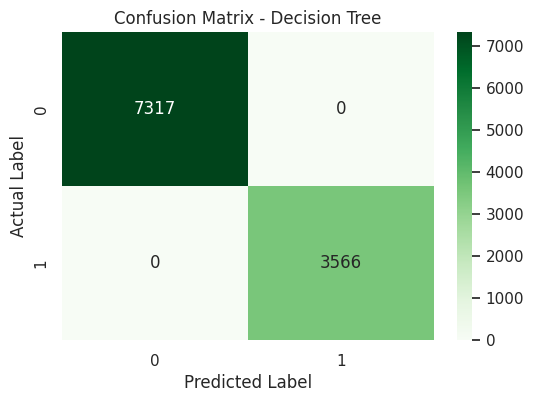

In [68]:
# Confusion Matrix for Decision Tree

cm_tree = confusion_matrix(y_test, y_pred_tree) # Generate confusion matrix for Decision Tree
print("Confusion Matrix for Decision Tree:") # Print the confusion matrix
print(cm_tree)
plt.figure(figsize=(6, 4)) # Plot the confusion matrix as a heatmap
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [69]:
#  Check Overfitting in Decision Tree
# Decision Trees often overfit, so this check is needed
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create an instance of the Decision Tree Classifier (re-initializing to ensure it's defined)
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

# Predict on the training data using the Decision Tree model
y_train_pred_tree = decision_tree_model.predict(X_train)

# Calculate training accuracy
train_accuracy_tree = accuracy_score(y_train, y_train_pred_tree)

# Calculate testing accuracy
test_accuracy_tree = accuracy_score(y_test, y_pred_tree)

# Print training and testing accuracy
print("Decision Tree Training Accuracy:", train_accuracy_tree)
print("Decision Tree Testing Accuracy :", test_accuracy_tree)

Decision Tree Training Accuracy: 1.0
Decision Tree Testing Accuracy : 1.0


**Insights**

If training accuracy is much higher than testing accuracy, the model is likely overfitting.

This is common in a default Decision Tree.

## Cross-Validation for Model Stability

In [70]:
from sklearn.model_selection import cross_val_score

# Cross-Validation for Decision Tree
# Define and fit the decision_tree_model
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

# Perform 5-fold cross-validation using recall as the scoring metric
cv_recall_tree = cross_val_score( decision_tree_model,X_train,y_train,cv=5,scoring='recall')
print("Decision Tree Cross-Validation Recall Scores:") # Print the recall scores from each fold
print(cv_recall_tree)
print("Mean CV Recall for Decision Tree:", cv_recall_tree.mean()) # Print the average cross-validation recall

Decision Tree Cross-Validation Recall Scores:
[1. 1. 1. 1. 1.]
Mean CV Recall for Decision Tree: 1.0


In [71]:
# Cross-Validation for Logistic Regression Using sklearn Equivalent

from sklearn.linear_model import LogisticRegression # Import LogisticRegression from sklearn only for cross-validation convenience
log_reg_cv = LogisticRegression(max_iter=1000, random_state=42) # Create a Logistic Regression model

# Perform 5-fold cross-validation using recall as the scoring metric
cv_recall_logit = cross_val_score(
    log_reg_cv,
    X_train,
    y_train,
    cv=5,
    scoring='recall'
)

print("Logistic Regression Cross-Validation Recall Scores:") # Print the recall scores from each fold
print(cv_recall_logit)
print("Mean CV Recall for Logistic Regression:", cv_recall_logit.mean()) # Print the average cross-validation recall

Logistic Regression Cross-Validation Recall Scores:
[1. 1. 1. 1. 1.]
Mean CV Recall for Logistic Regression: 1.0


## Compare Model Performance in One Table

In [72]:
# Create a DataFrame to compare both models across multiple evaluation metrics

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [accuracy_logit, accuracy_tree],
    'Precision': [precision_logit, precision_tree],
    'Recall': [recall_logit, recall_tree],
    'F1_Score': [f1_logit, f1_tree],
    'ROC_AUC': [roc_auc_logit, roc_auc_tree]
})
print(model_comparison) # Display the comparison table


                 Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
0  Logistic Regression       1.0        1.0     1.0       1.0      1.0
1        Decision Tree       1.0        1.0     1.0       1.0      1.0


##Model Performance Improvement

### Prepare a Separate Dataset for Logistic Regression

In [73]:
X_train_lr = X_train.copy() # Create copies of training and testing data for Logistic Regression tuning
X_test_lr = X_test.copy()

# Drop original columns that are exact parts of engineered columns
# This avoids perfect multicollinearity
X_train_lr = X_train_lr.drop(
    columns=[
        'no_of_weekend_nights',
        'no_of_week_nights',
        'no_of_adults',
        'no_of_children',
        'no_of_previous_cancellations',
        'no_of_previous_bookings_not_canceled'
    ],
    errors='ignore'
)

# Apply the same column drops to the test set
X_test_lr = X_test_lr.drop(
    columns=[
        'no_of_weekend_nights',
        'no_of_week_nights',
        'no_of_adults',
        'no_of_children',
        'no_of_previous_cancellations',
        'no_of_previous_bookings_not_canceled'
    ],
    errors='ignore'
)

constant_cols = [col for col in X_train_lr.columns if X_train_lr[col].nunique() <= 1] # Remove any constant columns from the training set

X_train_lr = X_train_lr.drop(columns=constant_cols, errors='ignore') # Drop the same constant columns from both training and testing sets
X_test_lr = X_test_lr.drop(columns=constant_cols, errors='ignore')

duplicate_cols = X_train_lr.T[X_train_lr.T.duplicated()].index.tolist() # Remove duplicate columns if any exist

X_train_lr = X_train_lr.drop(columns=duplicate_cols, errors='ignore') # Drop duplicate columns from both training and testing sets
X_test_lr = X_test_lr.drop(columns=duplicate_cols, errors='ignore')

X_train_lr = X_train_lr.astype(float) # Convert all columns to float so statsmodels can handle them correctly
X_test_lr = X_test_lr.astype(float)

y_train_lr = y_train.astype(int) # Convert target variables to integer type
y_test_lr = y_test.astype(int)

print("X_train_lr shape:", X_train_lr.shape) # Print the shapes after preparation
print("X_test_lr shape :", X_test_lr.shape)

X_train_lr shape: (25392, 20)
X_test_lr shape : (10883, 20)


##Check and Remove Multicollinearity Using VIF

In [74]:
X_train_vif = X_train_lr.copy() # Create a copy of the training set for VIF analysis

X_train_vif_const = sm.add_constant(X_train_vif) # Add a constant column for VIF calculation

vif_df = pd.DataFrame() # Create an empty DataFrame to store VIF values

vif_df["Feature"] = X_train_vif_const.columns # Store feature names

# Calculate VIF for every feature
vif_df["VIF"] = [
    variance_inflation_factor(X_train_vif_const.values, i)
    for i in range(X_train_vif_const.shape[1])
]

print(vif_df.sort_values(by="VIF", ascending=False)) # Display VIF values sorted from highest to lowest

                              Feature         VIF
0                               const  290.685164
20         market_segment_type_Online   67.107740
19        market_segment_type_Offline   60.477046
18      market_segment_type_Corporate   16.254425
17  market_segment_type_Complementary    4.224777
4                  avg_price_per_room    1.793783
1                           lead_time    1.564520
6              booking_status_encoded    1.514218
5              no_of_special_requests    1.392968
13     room_type_reserved_Room_Type 4    1.298816
10     type_of_meal_plan_Not Selected    1.237113
15     room_type_reserved_Room_Type 6    1.218248
8       type_of_meal_plan_Meal Plan 2    1.189793
7                        total_nights    1.109340
16     room_type_reserved_Room_Type 7    1.067028
2                       arrival_month    1.052490
11     room_type_reserved_Room_Type 2    1.031838
14     room_type_reserved_Room_Type 5    1.024950
9       type_of_meal_plan_Meal Plan 3    1.024750


In [75]:
X_train_vif_reduced = X_train_lr.copy() # Create a fresh copy of the training set for iterative VIF reduction

# Start a loop to iteratively remove high VIF variables
while True:

    X_temp = sm.add_constant(X_train_vif_reduced)  # Add constant term before VIF calculation

    vif_temp = pd.DataFrame() # Create a DataFrame to store VIF values
    vif_temp["Feature"] = X_temp.columns
    vif_temp["VIF"] = [
        variance_inflation_factor(X_temp.values, i)
        for i in range(X_temp.shape[1])
    ]

    vif_temp = vif_temp[vif_temp["Feature"] != "const"] # Remove the constant row because we do not use it for feature removal

    max_vif = vif_temp["VIF"].max()

    # Stop the loop if all VIF values are acceptable
    if max_vif <= 5:
        break

    feature_to_drop = vif_temp.sort_values(by="VIF", ascending=False)["Feature"].iloc[0] # Identify the feature with the highest VIF

    print(f"Dropping '{feature_to_drop}' due to high VIF = {max_vif:.2f}")  # Print the feature being removed

    X_train_vif_reduced = X_train_vif_reduced.drop(columns=[feature_to_drop])  # Drop the feature from the training set

print("Final features after VIF reduction:") # Print the final list of features after VIF reduction
print(X_train_vif_reduced.columns.tolist())

X_test_vif_reduced = X_test_lr[X_train_vif_reduced.columns] # Keep only the final VIF-selected columns in the test set

print("X_train_vif_reduced shape:", X_train_vif_reduced.shape) # Print the shapes after VIF reduction
print("X_test_vif_reduced shape :", X_test_vif_reduced.shape)

Dropping 'market_segment_type_Online' due to high VIF = 67.11
Final features after VIF reduction:
['lead_time', 'arrival_month', 'arrival_date', 'avg_price_per_room', 'no_of_special_requests', 'booking_status_encoded', 'total_nights', 'type_of_meal_plan_Meal Plan 2', 'type_of_meal_plan_Meal Plan 3', 'type_of_meal_plan_Not Selected', 'room_type_reserved_Room_Type 2', 'room_type_reserved_Room_Type 3', 'room_type_reserved_Room_Type 4', 'room_type_reserved_Room_Type 5', 'room_type_reserved_Room_Type 6', 'room_type_reserved_Room_Type 7', 'market_segment_type_Complementary', 'market_segment_type_Corporate', 'market_segment_type_Offline']
X_train_vif_reduced shape: (25392, 19)
X_test_vif_reduced shape : (10883, 19)


**Insights**

VIF helps remove highly correlated predictors.

Lower multicollinearity makes Logistic Regression more stable and interpretable.

##Fit Logistic Regression After VIF Reduction

In [76]:
X_train_sm = sm.add_constant(X_train_vif_reduced, has_constant='add') # Add constant term to the reduced training set

X_test_sm = sm.add_constant(X_test_vif_reduced, has_constant='add') # Add constant term to the reduced test set

logit_model = sm.Logit(y_train_lr, X_train_sm) # Build the Logistic Regression model

# Use fit_regularized for robustness against multicollinearity and numerical stability
logit_result = logit_model.fit_regularized(method='l1', alpha=0.0001, disp=False, maxiter=1000) # Fit the model

print(logit_result.summary()) # Print the model summary

                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25372
Method:                           MLE   Df Model:                           19
Date:                Sun, 26 Apr 2026   Pseudo R-squ.:                   1.000
Time:                        18:08:23   Log-Likelihood:             -0.0012770
converged:                       True   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const                               -19.1749    120.950     -0.159      0.874    -256.232     217.882
lead_time                             1.2603     36.952      0

/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 11 out of 20 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)


##Remove High p-value Variables

In [77]:
# Create a copy of the VIF-reduced training data for p-value based feature selection
X_train_p = X_train_vif_reduced.copy()

# Start an iterative loop to remove statistically insignificant variables
while True:

    # Add constant to the current feature set
    X_train_p_sm = sm.add_constant(X_train_p, has_constant='add')

    # Fit the Logistic Regression model on the current feature set using regularization for robustness
    model_p = sm.Logit(y_train_lr, X_train_p_sm).fit_regularized(method='l1', alpha=0.0001, disp=False, maxiter=1000)

    # Extract p-values from the fitted model
    # Let's assume `model_p.pvalues` will still work or coefficients will be near zero for insignificant features.
    p_values = model_p.pvalues

    # Remove the intercept from p-value consideration
    p_values = p_values.drop('const')

    # Find the largest p-value among predictors
    max_p = p_values.max()

    # Stop if all p-values are significant at 5% level
    if max_p <= 0.05:
        break

    # Identify the feature with the highest p-value
    feature_to_remove = p_values.idxmax()

    # Print which feature is being removed
    print(f"Removing '{feature_to_remove}' due to high p-value = {max_p:.4f}")

    # Drop the insignificant feature
    X_train_p = X_train_p.drop(columns=[feature_to_remove])

# Keep only the final selected columns in the test set
X_test_p = X_test_vif_reduced[X_train_p.columns]

# Add constant term to final train and test sets
X_train_final_sm = sm.add_constant(X_train_p, has_constant='add')
X_test_final_sm = sm.add_constant(X_test_p, has_constant='add')

# Fit the final Logistic Regression model using regularization for robustness
final_logit_model = sm.Logit(y_train_lr, X_train_final_sm)
final_logit_result = final_logit_model.fit_regularized(method='l1', alpha=0.0001, disp=False, maxiter=1000)

# Print the final model summary
print(final_logit_result.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 11 out of 20 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)


Removing 'room_type_reserved_Room_Type 3' due to high p-value = 1.0000


/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 11 out of 19 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)


Removing 'type_of_meal_plan_Meal Plan 3' due to high p-value = 1.0000


/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 11 out of 18 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 11 out of 17 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Tri

...

/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 8 out of 9 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 7 out of 8 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimmin

Removing 'no_of_special_requests' due to high p-value = 0.9996
Removing 'type_of_meal_plan_Meal Plan 2' due to high p-value = 0.9982


/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 7 out of 7 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 6 out of 6 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimmin

Removing 'arrival_date' due to high p-value = 0.9974
Removing 'arrival_month' due to high p-value = 0.9868
Removing 'type_of_meal_plan_Not Selected' due to high p-value = 0.9842
Removing 'total_nights' due to high p-value = 0.9753
Removing 'booking_status_encoded' due to high p-value = 0.9960
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25390
Method:                           MLE   Df Model:                            1
Date:                Sun, 26 Apr 2026   Pseudo R-squ.:               0.0002951
Time:                        18:08:31   Log-Likelihood:                -16055.
converged:                       True   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                  0.002080
                                     coef    std err          z      P>|z|

/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 3 out of 3 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  warnings.warn(msg, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:71: ConvergenceWarning: QC check did not pass for 2 out of 2 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  warnings.warn(message, ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/l1_solvers_common.py:144: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimmin

**Insights**

High p-value variables contribute little statistical evidence to the model.

Removing them helps simplify the model and improve interpretability.

##Determine the Optimal Threshold Using ROC Curve

Optimal Threshold: inf


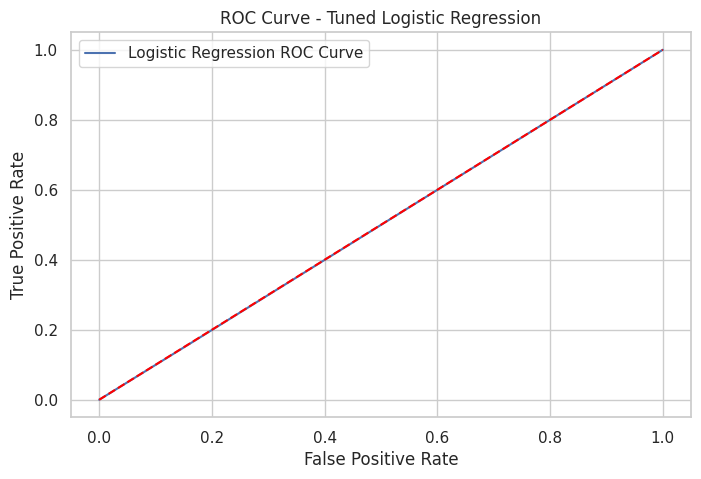

In [80]:
from sklearn.metrics import roc_curve

y_prob_logit_tuned = final_logit_result.predict(X_test_final_sm) # Predict probabilities on the test set using the final Logistic Regression model

fpr, tpr, thresholds = roc_curve(y_test_lr, y_prob_logit_tuned) # Calculate False Positive Rate, True Positive Rate, and threshold values

youden_index = tpr - fpr # Calculate Youden's J statistic for every threshold,Youden's J = TPR - FPR

optimal_idx = np.argmax(youden_index) # Find the index of the best threshold

optimal_threshold = thresholds[optimal_idx] # Extract the optimal threshold

print("Optimal Threshold:", optimal_threshold) # Print the optimal threshold

# Plot the ROC curve
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label='Logistic Regression ROC Curve')
plt.plot([0, 1], [0, 1], linestyle='--', color='red')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Logistic Regression")
plt.legend()
plt.show()

**Insights**

The default threshold 0.5 is not always best.

ROC-based threshold tuning can improve recall or overall balance.

##Predict Using the Optimal Threshold

In [81]:
y_pred_logit_tuned = (y_prob_logit_tuned >= optimal_threshold).astype(int) # Convert predicted probabilities into class labels using the optimal threshold

print("First 10 predicted probabilities:") # Display first 10 predicted probabilities
print(y_prob_logit_tuned[:10])

print("First 10 predicted classes:") # Display first 10 predicted classes
print(y_pred_logit_tuned[:10])

First 10 predicted probabilities:
32030    0.323549
17420    0.323549
29693    0.323549
30826    0.347970
28087    0.323549
8516     0.347970
6449     0.347970
11426    0.323549
29860    0.323549
11325    0.323549
dtype: float64
First 10 predicted classes:
32030    0
17420    0
29693    0
30826    0
28087    0
8516     0
6449     0
11426    0
29860    0
11325    0
dtype: int64


## Evaluate the Tuned Logistic Regression Model

Tuned Logistic Regression Performance:
Accuracy : 0.6723329964164293
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.4996493043075879
Classification Report - Tuned Logistic Regression
              precision    recall  f1-score   support

           0       0.67      1.00      0.80      7317
           1       0.00      0.00      0.00      3566

    accuracy                           0.67     10883
   macro avg       0.34      0.50      0.40     10883
weighted avg       0.45      0.67      0.54     10883



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

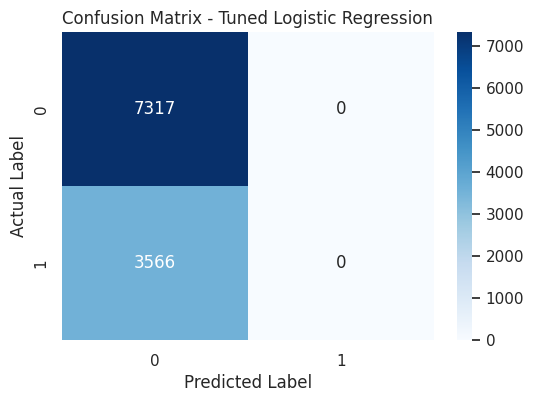

In [82]:
accuracy_logit_tuned = accuracy_score(y_test_lr, y_pred_logit_tuned) # Calculate evaluation metrics for tuned Logistic Regression
precision_logit_tuned = precision_score(y_test_lr, y_pred_logit_tuned)
recall_logit_tuned = recall_score(y_test_lr, y_pred_logit_tuned)
f1_logit_tuned = f1_score(y_test_lr, y_pred_logit_tuned)
roc_auc_logit_tuned = roc_auc_score(y_test_lr, y_prob_logit_tuned)

print("Tuned Logistic Regression Performance:") # Print the metrics
print("Accuracy :", accuracy_logit_tuned)
print("Precision:", precision_logit_tuned)
print("Recall   :", recall_logit_tuned)
print("F1 Score :", f1_logit_tuned)
print("ROC-AUC  :", roc_auc_logit_tuned)

print("Classification Report - Tuned Logistic Regression") # Print classification report for tuned Logistic Regression
print(classification_report(y_test_lr, y_pred_logit_tuned))

cm_logit_tuned = confusion_matrix(y_test_lr, y_pred_logit_tuned) # Create confusion matrix for tuned Logistic Regression

plt.figure(figsize=(6, 4)) # Plot the confusion matrix
sns.heatmap(cm_logit_tuned, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

##Tune Decision Tree Using Pre-Pruning

In [83]:
from sklearn.model_selection import GridSearchCV

# Pre-pruning controls tree complexity before the tree grows too much. This reduces overfitting.

dt_model = DecisionTreeClassifier(random_state=42) # Create a base Decision Tree model

# Define the hyperparameter grid for tuning
param_grid = {
    'max_depth': [3, 5, 7, 9, 12],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Create GridSearchCV object
# scoring='recall' is used because recall is the most important business metric
grid_search_dt = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
)

grid_search_dt.fit(X_train, y_train) # Fit GridSearchCV on training data

print("Best parameters for Decision Tree:") # Print the best hyperparameters found
print(grid_search_dt.best_params_)

print("Best cross-validation recall:") # Print the best cross-validation recall score
print(grid_search_dt.best_score_)

Best parameters for Decision Tree:
{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best cross-validation recall:
1.0


##Build the Tuned Decision Tree Model

In [85]:
# Extract the best tuned Decision Tree model
best_dt_model = grid_search_dt.best_estimator_

# Predict class labels on the test set
y_pred_dt_tuned = best_dt_model.predict(X_test)

# Predict probabilities on the test set
y_prob_dt_tuned = best_dt_model.predict_proba(X_test)[:, 1]

##Evaluate the Tuned Decision Tree Model

Tuned Decision Tree Performance:
Accuracy : 0.8694293852797942
Precision: 0.8194816800714924
Recall   : 0.7714526079641054
F1 Score : 0.7947421638018201
ROC-AUC  : 0.9196898624435862
Classification Report - Tuned Decision Tree
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      7317
           1       0.82      0.77      0.79      3566

    accuracy                           0.87     10883
   macro avg       0.86      0.84      0.85     10883
weighted avg       0.87      0.87      0.87     10883



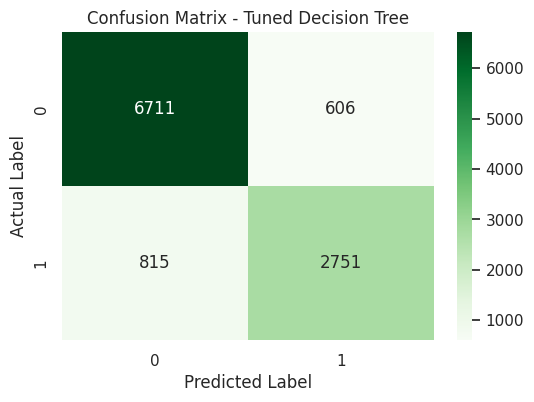

In [122]:
accuracy_dt_tuned = accuracy_score(y_test, y_pred_dt_tuned) # Calculate evaluation metrics for tuned Decision Tree
precision_dt_tuned = precision_score(y_test, y_pred_dt_tuned)
recall_dt_tuned = recall_score(y_test, y_pred_dt_tuned)
f1_dt_tuned = f1_score(y_test, y_pred_dt_tuned)
roc_auc_dt_tuned = roc_auc_score(y_test, y_prob_dt_tuned)

print("Tuned Decision Tree Performance:") # Print evaluation metrics
print("Accuracy :", accuracy_dt_tuned)
print("Precision:", precision_dt_tuned)
print("Recall   :", recall_dt_tuned)
print("F1 Score :", f1_dt_tuned)
print("ROC-AUC  :", roc_auc_dt_tuned)

print("Classification Report - Tuned Decision Tree") # Print classification report for tuned Decision Tree
print(classification_report(y_test, y_pred_dt_tuned))

cm_dt_tuned = confusion_matrix(y_test, y_pred_dt_tuned) # Create confusion matrix for tuned Decision Tree

plt.figure(figsize=(6, 4)) # Plot the confusion matrix
sns.heatmap(cm_dt_tuned, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Tuned Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

##Compare Untuned and Tuned Models

In [123]:
# Create a comparison table for tuned models
tuned_model_comparison = pd.DataFrame({
    'Model': ['Tuned Logistic Regression', 'Tuned Decision Tree'],
    'Accuracy': [accuracy_logit_tuned, accuracy_dt_tuned],
    'Precision': [precision_logit_tuned, precision_dt_tuned],
    'Recall': [recall_logit_tuned, recall_dt_tuned],
    'F1_Score': [f1_logit_tuned, f1_dt_tuned],
    'ROC_AUC': [roc_auc_logit_tuned, roc_auc_dt_tuned]
})

# Display the comparison table
print(tuned_model_comparison)

                       Model  Accuracy  Precision    Recall  F1_Score  \
0  Tuned Logistic Regression  0.773684   0.621076  0.793326  0.696712   
1        Tuned Decision Tree  0.869429   0.819482  0.771453  0.794742   

    ROC_AUC  
0  0.861916  
1  0.919690  


##Model Performance Comparison and Final Model Selection

In [124]:
#  Create a Model Comparison Table

# Each row represents one model
# Each column represents one evaluation metric
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Tuned Logistic Regression',
        'Tuned Decision Tree'
    ],

    # Store accuracy values for each model
    'Accuracy': [
        accuracy_logit,
        accuracy_tree,
        accuracy_logit_tuned,
        accuracy_dt_tuned
    ],

    # Store precision values for each model
    'Precision': [
        precision_logit,
        precision_tree,
        precision_logit_tuned,
        precision_dt_tuned
    ],

    # Store recall values for each model
    'Recall': [
        recall_logit,
        recall_tree,
        recall_logit_tuned,
        recall_dt_tuned
    ],

    # Store F1-score values for each model
    'F1_Score': [
        f1_logit,
        f1_tree,
        f1_logit_tuned,
        f1_dt_tuned
    ],

    # Store ROC-AUC values for each model
    'ROC_AUC': [
        roc_auc_logit,
        roc_auc_tree,
        roc_auc_logit_tuned,
        roc_auc_dt_tuned
    ]
})

# Display the comparison table
print("Model Performance Comparison Table:")
print(model_comparison)


Model Performance Comparison Table:
                       Model  Accuracy  Precision    Recall  F1_Score  \
0        Logistic Regression  0.806120   0.736057  0.636568  0.682707   
1              Decision Tree  0.863365   0.784405  0.803982  0.794073   
2  Tuned Logistic Regression  0.773684   0.621076  0.793326  0.696712   
3        Tuned Decision Tree  0.869429   0.819482  0.771453  0.794742   

    ROC_AUC  
0  0.862204  
1  0.851965  
2  0.861916  
3  0.919690  


**Insights**

This table gives a side-by-side comparison of all models.

It helps us identify which model performs best on recall and how that compares with other metrics.

In [125]:
#Round the Table for Better Presentation

model_comparison_rounded = model_comparison.copy() # Round all metric values to 4 decimal places for neat presentation

# Round selected metric columns
model_comparison_rounded[['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']] = (
    model_comparison_rounded[['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']].round(4)
)

print("Rounded Model Comparison Table:") # Display the rounded comparison table
print(model_comparison_rounded)

Rounded Model Comparison Table:
                       Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
0        Logistic Regression    0.8061     0.7361  0.6366    0.6827   0.8622
1              Decision Tree    0.8634     0.7844  0.8040    0.7941   0.8520
2  Tuned Logistic Regression    0.7737     0.6211  0.7933    0.6967   0.8619
3        Tuned Decision Tree    0.8694     0.8195  0.7715    0.7947   0.9197


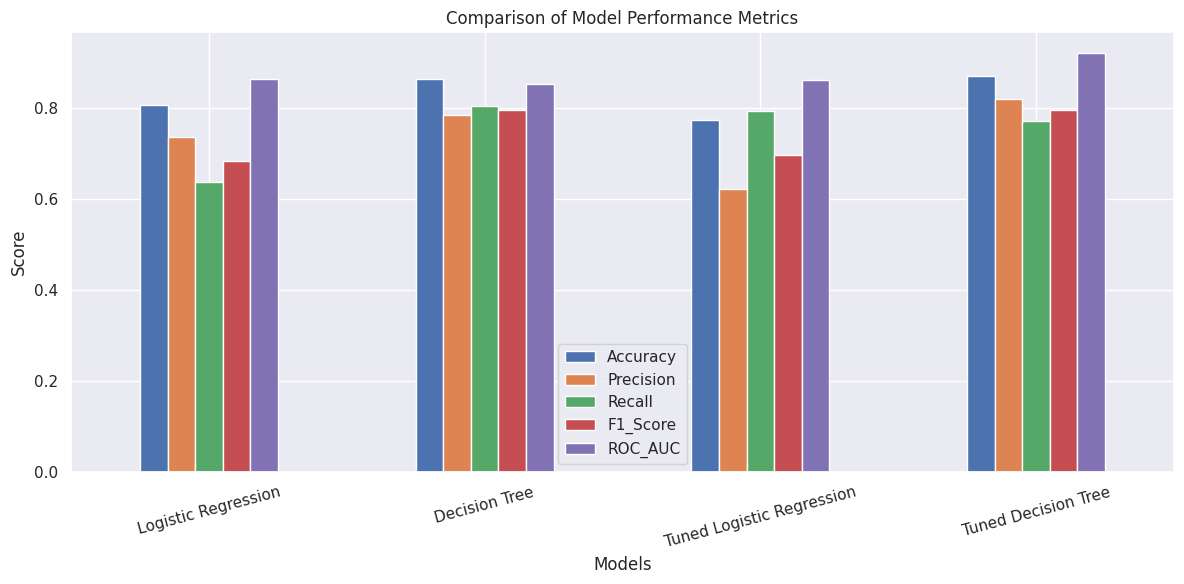

In [126]:
# Visual Comparison of Model Metrics

comparison_plot_df = model_comparison.set_index('Model') # Set the model names as the index for easier plotting

# Create a bar plot for comparing model metrics
comparison_plot_df.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Comparison of Model Performance Metrics") # Set the title of the plot

plt.xlabel("Models") # Label the x-axis

plt.ylabel("Score") # Label the y-axis

plt.xticks(rotation=15) # Rotate x-axis labels slightly for readability

plt.legend(loc='best') # Show legend

plt.tight_layout() # Adjust layout so labels fit properly

plt.show() # Display the plot

**Insights **

This plot helps visually compare the performance of all models across all metrics.

It makes it easier to identify which model is strongest overall and which one is strongest specifically on recall.

In [127]:
# Rank Models by Recall

recall_ranking = model_comparison.sort_values(by='Recall', ascending=False) # Sort the model comparison table by Recall in descending order

print("Models Ranked by Recall:") # Display the ranking
print(recall_ranking[['Model', 'Recall', 'Precision', 'F1_Score', 'ROC_AUC']])

Models Ranked by Recall:
                       Model    Recall  Precision  F1_Score   ROC_AUC
1              Decision Tree  0.803982   0.784405  0.794073  0.851965
2  Tuned Logistic Regression  0.793326   0.621076  0.696712  0.861916
3        Tuned Decision Tree  0.771453   0.819482  0.794742  0.919690
0        Logistic Regression  0.636568   0.736057  0.682707  0.862204


**Insights**

The model at the top of this ranking is the strongest candidate if business priority is to identify as many cancellations as possible.

In [128]:
# Select the Best Model

best_model_row = model_comparison.loc[model_comparison['Recall'].idxmax()] # Identify the best model based on the highest Recall

print("Best Model Based on Recall:") # Print the best model details
print(best_model_row)

Best Model Based on Recall:
Model        Decision Tree
Accuracy          0.863365
Precision         0.784405
Recall            0.803982
F1_Score          0.794073
ROC_AUC           0.851965
Name: 1, dtype: object


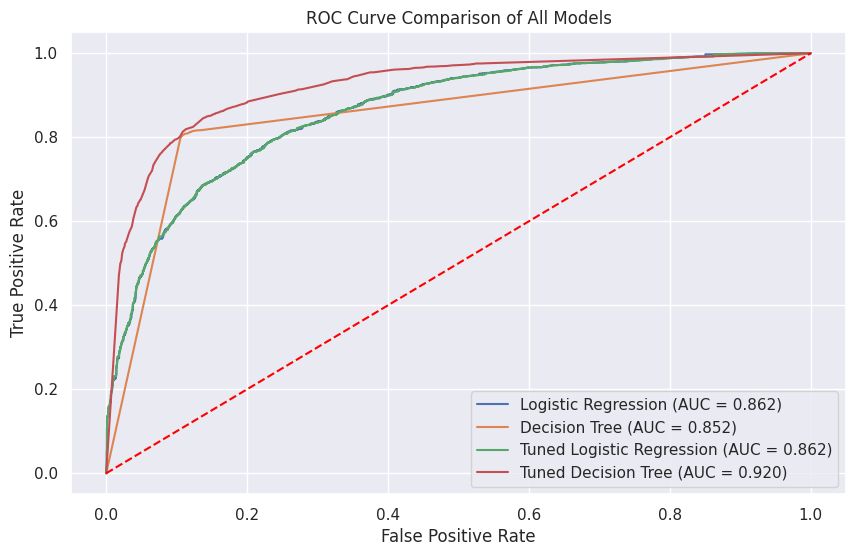

In [129]:
# Compare ROC Curves Visually

# Import roc_curve for plotting ROC curves
from sklearn.metrics import roc_curve

# Calculate ROC points for Logistic Regression
fpr_logit, tpr_logit, _ = roc_curve(y_test, y_prob_logit)

# Calculate ROC points for Decision Tree
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)

# Calculate ROC points for Tuned Logistic Regression
fpr_logit_tuned, tpr_logit_tuned, _ = roc_curve(y_test, y_prob_logit_tuned)

# Calculate ROC points for Tuned Decision Tree
fpr_dt_tuned, tpr_dt_tuned, _ = roc_curve(y_test, y_prob_dt_tuned)

# Create the ROC curve plot
plt.figure(figsize=(10, 6))

# Plot ROC curve for Logistic Regression
plt.plot(fpr_logit, tpr_logit, label=f'Logistic Regression (AUC = {roc_auc_logit:.3f})')

# Plot ROC curve for Decision Tree
plt.plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {roc_auc_tree:.3f})')

# Plot ROC curve for Tuned Logistic Regression
plt.plot(fpr_logit_tuned, tpr_logit_tuned, label=f'Tuned Logistic Regression (AUC = {roc_auc_logit_tuned:.3f})')

# Plot ROC curve for Tuned Decision Tree
plt.plot(fpr_dt_tuned, tpr_dt_tuned, label=f'Tuned Decision Tree (AUC = {roc_auc_dt_tuned:.3f})')

# Plot the diagonal reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='red')

# Add title and axis labels
plt.title("ROC Curve Comparison of All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

# Show the legend
plt.legend(loc='lower right')

# Display the plot
plt.show()

**Insights**

The ROC curve helps compare models across all classification thresholds.

A model with a curve closer to the top-left corner is generally better.